# Stage 2: Stochastic IQL-Warp + Epistemic Penalty + CAPS + Physics Safety Shield

- **Phan hoach:** Balanced 3-Fold Building-Scaffold tu `collect_and_profile.ipynb` (zero data leak giua cac toa nha).
- **Kien truc RL an toan:** `DeepSetsWarpResiPActor` (Rational Quadratic Spline bi chan dao ham `[0.40, 2.20]` + Physics-Uncertainty Gate tu `model_error`) + `DeepSetsValueNet` + `DeepSetsAHUTwinCritic`.
- **Thuat toan Offline RL:** Implicit Q-Learning (Expectile `tau = 0.70`) + Epistemic Advantage Weighted Regression (`Q_cons = min(Q1, Q2) - 0.5 * |Q1 - Q2|`) + Chuan hoa Reward tuyen tinh (`r / std`, loai bo `symlog`) + CAPS (Temporal & Spatial smoothness).
- **Physics Safety Shield:** Chan moi lenh AHU lam tang comfort penalty 1-step hoac bop boiler khi zone dang can suoi.


In [ ]:
%%writefile /kaggle/working/physics_foundation.py
"""Physics Foundation: TransferPolicy -> EmptyDayConsistentPolicy
Attribution: Daniel Wu, jazivxt (Facilities V42), penguin069 (Deep Setback)
Source: https://www.kaggle.com/code/penguin069/smart-buildings-empty-day-consistent-model
No neural weights. Only metadata and observations enter decisions.
"""
import math
import re
from collections import deque
import numpy as np


class TransferPolicy:
    'A transferable controller implementing the official two-method API.'
    name = 'adaptive_physics'
    DEFAULTS = {
        'comfort_margin': 0.12, 'precondition_hours': 1.0, 'recovery_steps': 1.5,
        'forgetting_factor': 0.997, 'model_residual_gain': 0.16, 'comfort_cost': 65000.0,
        'gas_cost_ratio': 0.30, 'hot_water_target': 345.0, 'standby_minimum': 282.0,
        'standby_maximum': 307.0, 'observation_delay': 1, 'response_scale': 0.75,
        'disturbance_rate': 0.35,
    }
    AIR_CAPACITY = 1.2 * 1006.0
    WATER_VALVE_CAPACITY = 4180.0 * 1000.0 * 0.108 / 3600.0
    DESIGN_PRESSURE = 2000.0
    MIN_PRESSURE = 200.0
    MIN_DAMPER = 0.10
    MAX_RECIRCULATION = 0.70
    MAX_DISCHARGE_K = 308.15

    def __init__(self, building_meta_data, action_spec=None, parameters=None):
        self.metadata = building_meta_data
        self.action_spec = action_spec
        self.parameters = dict(self.DEFAULTS)
        if parameters:
            self.parameters.update(parameters)
        self.n_continuous = int(building_meta_data['n_continuous_action'])
        self.n_discrete = int(building_meta_data['n_discrete_action'])
        self.field_names = [str(x) for x in building_meta_data['observation_field_names']]
        self.field_index = {name: i for i, name in enumerate(self.field_names)}
        self.obs_norm = building_meta_data.get('observation_normalization_metadata', {})
        self.action_norm = building_meta_data.get('action_normalization_metadata', {})
        self.temp_indices = list(building_meta_data['temp_indices'])
        self.pressure_indices = list(building_meta_data['pressure_indices'])
        self.recirculation_indices = list(building_meta_data['recirculation_indices'])
        self.water_indices = list(building_meta_data['water_indices'])
        self.num_ahus = len(self.temp_indices)
        zone_actions = building_meta_data['zone_action_indices']
        self.zone_ids = sorted(zone_actions, key=self._natural_key)
        self.n_zones = len(self.zone_ids)
        self.zone_number = {name: i for i, name in enumerate(self.zone_ids)}
        self.zone_obs = np.array([
            self.field_index.get(f'{z}_zone_air_temperature_sensor', -1) for z in self.zone_ids
        ], dtype=int)
        self.zone_low_obs = np.array([
            self.field_index.get(f'{z}_zone_air_heating_temperature_setpoint_sensor', -1) for z in self.zone_ids
        ], dtype=int)
        self.zone_high_obs = np.array([
            self.field_index.get(f'{z}_zone_air_cooling_temperature_setpoint_sensor', -1) for z in self.zone_ids
        ], dtype=int)
        self.zone_flow_obs = np.array([
            self.field_index.get(f'{z}_supply_air_flowrate_setpoint', -1) for z in self.zone_ids
        ], dtype=int)
        self.damper_indices = np.array([
            zone_actions[z]['supply_air_damper_percentage_command'] for z in self.zone_ids
        ], dtype=int)
        self.valve_indices = np.array([
            zone_actions[z]['reheat_valve_percentage_command'] for z in self.zone_ids
        ], dtype=int)
        assignments = building_meta_data.get('ahu_zone_assignments', building_meta_data.get('aha_zone_assignments', {}))
        self.ahu_ids = sorted(assignments, key=self._natural_key)
        self.groups = []
        self.zone_ahu = np.zeros(self.n_zones, dtype=int)
        self.outside_obs = []
        for i, ahu in enumerate(self.ahu_ids):
            group = np.array([
                self.zone_number[str(room).replace('room_', 'VAV_')]
                for room in assignments[ahu]
                if str(room).replace('room_', 'VAV_') in self.zone_number
            ], dtype=int)
            self.groups.append(group)
            self.zone_ahu[group] = i
            self.outside_obs.append(self._find_field(
                f'ahs_{ahu}_outside_air_temperature_sensor',
                f'{ahu}_outside_air_temperature_sensor',
                suffix='outside_air_temperature_sensor'))
        self.water_sensor = self._find_field(suffix='supply_water_temperature_sensor')
        self.comfort_now_index = self.field_index.get('comfort_mode_now')
        self.comfort_soon_index = self.field_index.get('comfort_mode_soon')
        self.occupancy_index = self.field_index.get('num_occupants')
        self.comfort_band = tuple(map(float, building_meta_data['comfort_temp_window']))
        self.eco_band = tuple(map(float, building_meta_data['eco_temp_window']))
        self.start_hour = float(building_meta_data.get('morning_start_hour', 6))
        self.end_hour = float(building_meta_data.get('evening_start_hour', 19))
        self.zone_area, self.zone_ua = self._geometry_priors(building_meta_data.get('zone_map'))
        effective_capacity = 3800.0 * self.zone_area + 21000.0 * np.sqrt(self.zone_area)
        self.initial_gain = np.clip(300000.0 / effective_capacity, 0.08, 2.5)
        self.reset()

    @staticmethod
    def _natural_key(value):
        return tuple(int(x) if x.isdigit() else x for x in re.split(r'(\d+)', str(value)))

    def _find_field(self, *exact, suffix=''):
        for name in exact:
            if name in self.field_index:
                return self.field_index[name]
        if suffix:
            for name, index in self.field_index.items():
                if name.endswith(suffix):
                    return index
        return None

    def _geometry_priors(self, zone_map):
        areas = np.full(self.n_zones, 55.0)
        ua = np.full(self.n_zones, 18.0)
        if zone_map is None:
            return areas, ua
        grid = np.asarray(zone_map)
        if grid.ndim != 2 or grid.size > 5000000:
            return areas, ua
        height, width = grid.shape
        inside = (grid == 0).ravel()
        visited = np.zeros(grid.size, dtype=bool)
        flat = grid.ravel()
        counts, external_edges = [], []
        for start in np.flatnonzero(inside):
            if visited[start]:
                continue
            stack = [int(start)]
            visited[start] = True
            count, edge = 0, 0
            while stack:
                p = stack.pop()
                count += 1
                row, col = divmod(p, width)
                for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
                    nr, nc = row + dr, col + dc
                    if not (0 <= nr < height and 0 <= nc < width):
                        continue
                    q = nr * width + nc
                    if inside[q] and not visited[q]:
                        visited[q] = True
                        stack.append(q)
                    elif flat[q] == 2:
                        edge += 1
                    elif flat[q] == 1:
                        rr, cc = row + 2 * dr, col + 2 * dc
                        if 0 <= rr < height and 0 <= cc < width and grid[rr, cc] == 2:
                            edge += 1
            counts.append(count)
            external_edges.append(edge)
        if len(counts) != self.n_zones:
            return areas, ua
        for j, name in enumerate(self.zone_ids):
            match = re.search(r'(\d+)$', name)
            label = int(match.group(1)) - 1 if match else j
            if 0 <= label < len(counts):
                areas[j] = max(1.0, 0.04 * counts[label])
                ua[j] = max(0.5, external_edges[label] * 0.2 * 3.0 * 1.3)
        return areas, ua

    def reset(self):
        self.step_count = 0
        self.history = deque(maxlen=3)
        self.previous_observed = None
        self.slow_temperature = None
        self.residual = np.zeros(self.n_zones)
        self.model_error = np.full(self.n_zones, 0.08)
        self.theta = np.zeros((self.n_zones, 6))
        self.theta[:, 0] = self.initial_gain * self.zone_area * 2.0 / 1000.0
        self.theta[:, 1] = self.initial_gain * self.zone_ua * 20.0 / 1000.0
        self.theta[:, 2] = 0.18
        self.theta[:, 3] = 0.08
        self.theta[:, 4] = self.initial_gain * self.zone_area * 8.0 / 1000.0
        self.theta[:, 5] = self.initial_gain * self.parameters['response_scale']
        self.theta[:, :2] *= self.parameters['response_scale']
        self.theta[:, 4] *= self.parameters['response_scale']
        prior = np.array([0.12, 0.20, 0.15, 0.15, 0.16, 0.8])
        self.covariance = np.repeat(np.diag(prior)[None, :, :], self.n_zones, axis=0)
        self.last_heating_step = -1000
        self.last_action = None

    def _temperature(self, obs, index, kind, fallback):
        if index is None:
            return fallback
        value = float(obs[index])
        if 150.0 < value < 450.0:
            return value
        norm = self.obs_norm.get(kind, {})
        mean = float(norm.get('sample_mean', fallback))
        std = float(norm.get('sample_std', math.sqrt(norm.get('sample_variance', 1.0))))
        value = value * std + mean
        return value if np.isfinite(value) and 150.0 < value < 450.0 else fallback

    def _zone_temperatures(self, obs):
        norm = self.obs_norm.get('zone_air_temperature_sensor', {})
        mean = float(norm.get('sample_mean', 295.0))
        std = float(norm.get('sample_std', math.sqrt(norm.get('sample_variance', 25.0))))
        raw = obs[self.zone_obs].astype(float)
        value = np.where((raw > 150.0) & (raw < 450.0), raw, raw * std + mean)
        fallback = self.previous_observed if self.previous_observed is not None else mean
        return np.where(np.isfinite(value) & (value > 150.0) & (value < 450.0), value, fallback)

    def _hour(self, obs):
        sine = self.field_index.get('hod_sin_000')
        cosine = self.field_index.get('hod_cos_000')
        if sine is None or cosine is None:
            return (self.start_hour + self.step_count / 12.0) % 24.0
        return (math.atan2(float(obs[sine]), float(obs[cosine])) % (2.0 * math.pi)) * 12.0 / math.pi

    def _band(self, obs, temperature):
        now = bool(obs[self.comfort_now_index] > 0.5) if self.comfort_now_index is not None else (
            self.start_hour <= self._hour(obs) < self.end_hour)
        soon = bool(obs[self.comfort_soon_index] > 0.5) if self.comfort_soon_index is not None else now
        default = self.comfort_band if now else self.eco_band
        low = np.full(self.n_zones, default[0])
        high = np.full(self.n_zones, default[1])
        valid = (self.zone_low_obs >= 0) & (self.zone_high_obs >= 0)
        if np.any(valid):
            sensor_low = obs[self.zone_low_obs[valid]].astype(float)
            sensor_high = obs[self.zone_high_obs[valid]].astype(float)
            good = (sensor_low > 150.0) & (sensor_high < 450.0) & (sensor_high > sensor_low)
            indices = np.flatnonzero(valid)[good]
            low[indices] = sensor_low[good]
            high[indices] = sensor_high[good]
        if now:
            low = np.maximum(low, self.comfort_band[0])
            high = np.minimum(high, self.comfort_band[1])
        elif soon:
            hour = self._hour(obs)
            remaining = max(0.0, (self.start_hour - hour) % 24.0)
            progress = np.clip(1.0 - remaining / max(0.1, self.parameters['precondition_hours']), 0.0, 1.0)
            low = self.eco_band[0] + progress * (self.comfort_band[0] - self.eco_band[0]) + np.zeros(self.n_zones)
            high = self.eco_band[1] + progress * (self.comfort_band[1] - self.eco_band[1]) + np.zeros(self.n_zones)
        else:
            low[:] = self.parameters['standby_minimum']
            high[:] = self.parameters['standby_maximum']
        margin = self.parameters['comfort_margin'] if (now or soon) else 0.0
        low += margin
        high -= margin
        recovery = max(1.0, self.parameters['recovery_steps'])
        low = np.minimum(low, temperature + np.maximum((low - temperature) / recovery, 0.0))
        high = np.maximum(high, temperature - np.maximum((temperature - high) / recovery, 0.0))
        return low, high, now

    def _group_temperature(self, temperature):
        means = np.zeros(self.n_zones)
        for group in self.groups:
            if group.size:
                means[group] = np.average(temperature[group], weights=self.zone_area[group])
        return means

    def _features(self, temperature, outside, mode, slow):
        return np.column_stack((
            np.ones(self.n_zones),
            np.clip((outside - temperature) / 20.0, -5.0, 5.0),
            np.clip((slow - temperature) / 5.0, -5.0, 5.0),
            np.clip((self._group_temperature(temperature) - temperature) / 5.0, -5.0, 5.0),
            np.full(self.n_zones, float(mode)),
        ))

    def _learn(self, observed):
        delay = int(self.parameters['observation_delay'])
        if self.previous_observed is None or len(self.history) <= delay:
            return
        applied = list(self.history)[-(delay + 1)]
        old = self.previous_observed
        power = (applied['conductance'] * (applied['supply'] - observed) + applied['reheat']) / 1000.0
        features = self._features(old, applied['outside'], applied['mode'], applied['slow'])
        x = np.column_stack((features, power))
        delta = np.clip(observed - old, -15.0, 15.0)
        prediction = np.einsum('ij,ij->i', self.theta, x)
        remaining = delta - prediction
        rate = float(self.parameters['disturbance_rate'])
        self.model_error = 0.94 * self.model_error + 0.06 * np.minimum(np.abs(remaining - self.residual), 2.0)
        self.residual = np.clip((1.0 - rate) * self.residual + rate * remaining, -5.0, 5.0)

    def _free_drift(self, temperature, outside, mode):
        features = self._features(temperature, outside, mode, self.slow_temperature)
        return np.clip(np.einsum('ij,ij->i', self.theta[:, :5], features) + self.residual, -5.0, 5.0)

    def _native_action(self, kind, value, low, high):
        spec = self.action_norm.get(kind)
        if spec is None:
            spec = next((v for k, v in self.action_norm.items() if str(k).endswith(kind)), None)
        if spec:
            low = float(spec.get('min_native_value', low))
            high = float(spec.get('max_native_value', high))
            out_low = float(spec.get('min_normalized_value', -1.0))
            out_high = float(spec.get('max_normalized_value', 1.0))
        else:
            out_low, out_high = -1.0, 1.0
        return np.clip(out_low + (np.asarray(value) - low) * (out_high - out_low) / max(high - low, 1e-12), out_low, out_high)

    def _choose_ahu(self, group, temperature, free, low, high, max_flow, outside, water):
        t, d, lo, hi = temperature[group], free[group], low[group], high[group]
        response = self.theta[group, 5]
        capacity = max_flow[group]
        inside = float(np.average(t, weights=self.zone_area[group]))
        targets = np.array([285.0, 287.0, 289.0, 291.0, 293.0, 295.0, 297.0, 299.0, 302.0, 305.0])
        targets = np.concatenate((targets, [float(np.clip(np.min(hi) - 1.5, 285.0, 305.0))]))
        setpoint = np.repeat(targets, 2)
        recirc = np.full_like(setpoint, self.MAX_RECIRCULATION)
        if outside < inside - 0.5:
            recirc[1::2] = np.clip((targets - outside) / max(inside - outside, 1e-6), 0.0, self.MAX_RECIRCULATION)
        mixed = recirc * inside + (1.0 - recirc) * outside
        supply = np.minimum(mixed, setpoint)
        sa = supply[:, None]
        cool_need = np.maximum(t + d - hi, 0.0) * 1000.0 / response
        heat_need = np.maximum(lo - t - d, 0.0) * 1000.0 / response
        cooling_flow = cool_need[None, :] / (self.AIR_CAPACITY * np.maximum(hi[None, :] - sa, 0.05))
        heating_flow = heat_need[None, :] / (self.AIR_CAPACITY * np.maximum(self.MAX_DISCHARGE_K - lo[None, :], 0.5))
        maximum_water_heat = self.WATER_VALVE_CAPACITY * math.sqrt(20.0) * np.maximum(water - sa, 0.0)
        maximum_heating_flow = maximum_water_heat / (self.AIR_CAPACITY * np.maximum(self.MAX_DISCHARGE_K - sa, 0.1))
        heating_flow = np.minimum(heating_flow, maximum_heating_flow)
        needed_flow = np.maximum(cooling_flow, heating_flow)
        fraction = np.max(needed_flow / capacity[None, :], axis=1)
        pressure = np.clip(self.DESIGN_PRESSURE * fraction ** 2, self.MIN_PRESSURE, self.DESIGN_PRESSURE)
        pressure_ratio = np.sqrt(pressure / self.DESIGN_PRESSURE)
        dampers = np.clip(needed_flow / (capacity[None, :] * pressure_ratio[:, None]), self.MIN_DAMPER, 1.0)
        flow = dampers * capacity[None, :] * pressure_ratio[:, None]
        conductance = flow * self.AIR_CAPACITY
        water_gap = np.maximum(water - sa, 0.0)
        wanted_reheat = np.maximum(
            (lo[None, :] - t[None, :] - d[None, :]) * 1000.0 / response[None, :] + conductance * (lo[None, :] - sa), 0.0)
        reheat_limit = np.minimum(
            conductance * np.maximum(self.MAX_DISCHARGE_K - sa, 0.0),
            self.WATER_VALVE_CAPACITY * math.sqrt(20.0) * water_gap)
        reheat = np.minimum(wanted_reheat, reheat_limit)
        predicted = (t[None, :] + d[None, :] + response[None, :] * (conductance * sa + reheat) / 1000.0) / (
            1.0 + response[None, :] * conductance / 1000.0)
        violation = np.maximum(lo[None, :] - predicted, 0.0) + np.maximum(predicted - hi[None, :], 0.0)
        thermal_penalty = np.sum(violation + 2.0 * violation ** 2, axis=1)
        total_flow = flow.sum(axis=1)
        fan = total_flow * pressure * (2.0 - recirc) / 0.9
        chiller = total_flow * self.AIR_CAPACITY * np.maximum(mixed - supply, 0.0) / 3.5
        gas = reheat.sum(axis=1)
        objective = fan + chiller + self.parameters['gas_cost_ratio'] * gas
        objective += self.parameters['comfort_cost'] * thermal_penalty
        off_prediction = t + d
        off_violation = np.maximum(lo - off_prediction, 0.0) + np.maximum(off_prediction - hi, 0.0)
        off_objective = self.parameters['comfort_cost'] * np.sum(off_violation + 2.0 * off_violation ** 2)
        best = int(np.argmin(objective))
        if off_objective <= objective[best]:
            return {'run': 0, 'pressure': 0.0, 'setpoint': 305.0, 'recirc': 0.7,
                    'damper': np.full(group.size, self.MIN_DAMPER), 'conductance': np.zeros(group.size),
                    'supply': np.full(group.size, mixed[best]), 'reheat': np.zeros(group.size)}
        return {'run': 1, 'pressure': float(pressure[best]), 'setpoint': float(setpoint[best]),
                'recirc': float(recirc[best]), 'damper': dampers[best],
                'conductance': conductance[best], 'supply': np.full(group.size, supply[best]),
                'reheat': reheat[best]}

    def get_action(self, obs):
        obs = np.asarray(obs, dtype=float).reshape(-1)
        observed = self._zone_temperatures(obs)
        if self.slow_temperature is None:
            self.slow_temperature = observed.copy()
        self._learn(observed)
        outside_ahu = np.array([
            self._temperature(obs, index, 'outside_air_temperature_sensor', 290.0)
            for index in self.outside_obs
        ])
        outside = outside_ahu[self.zone_ahu]
        mode = bool(obs[self.comfort_now_index] > 0.5) if self.comfort_now_index is not None else True
        temperature = observed.copy()
        if self.history and int(self.parameters['observation_delay']) == 1:
            last = self.history[-1]
            drift = self._free_drift(observed, last['outside'], last['mode'])
            gain = self.theta[:, 5] / 1000.0
            temperature = (observed + drift + gain * (last['conductance'] * last['supply'] + last['reheat'])) / (
                1.0 + gain * last['conductance'])
            temperature = np.clip(temperature, observed - 8.0, observed + 8.0)
        low, high, mode = self._band(obs, temperature)
        free = self._free_drift(temperature, outside, mode)
        max_flow = np.full(self.n_zones, 2.0)
        valid = self.zone_flow_obs >= 0
        if np.any(valid):
            flow_reading = obs[self.zone_flow_obs[valid]]
            max_flow[valid] = np.where(np.isfinite(flow_reading) & (flow_reading > 0.0), flow_reading, 2.0)
        max_flow = np.clip(max_flow, 0.01, 100.0)
        water_observed = self._temperature(obs, self.water_sensor, 'supply_water_temperature_sensor', 340.0)
        heat_demand = np.any(temperature + free < low)
        if heat_demand:
            self.last_heating_step = self.step_count
        recent_heat = self.step_count - self.last_heating_step < 24
        water_target = self.parameters['hot_water_target'] if recent_heat else 310.0
        water_available = water_observed
        continuous = np.full(self.n_continuous, -1.0, dtype=np.float32)
        discrete = np.zeros(self.n_discrete, dtype=np.int32)
        conductance = np.zeros(self.n_zones)
        supply = outside.copy()
        reheat = np.zeros(self.n_zones)
        for i, group in enumerate(self.groups):
            if not group.size:
                continue
            choice = self._choose_ahu(group, temperature, free, low, high, max_flow,
                                      float(outside_ahu[i]), float(water_available))
            discrete[i] = choice['run']
            continuous[self.temp_indices[i]] = self._native_action(
                f'{self.ahu_ids[i]}_supply_air_temperature_setpoint', choice['setpoint'], 285.0, 305.0)
            continuous[self.pressure_indices[i]] = self._native_action(
                f'{self.ahu_ids[i]}_supply_air_static_pressure_setpoint', choice['pressure'], 0.0, 2000.0)
            continuous[self.recirculation_indices[i]] = self._native_action(
                f'{self.ahu_ids[i]}_recirculation_percentage_command', choice['recirc'], 0.0, 1.0)
            continuous[self.damper_indices[group]] = self._native_action(
                'supply_air_damper_percentage_command', choice['damper'], 0.0, 1.0)
            conductance[group] = choice['conductance']
            supply[group] = choice['supply']
            reheat[group] = choice['reheat']
        if np.any(reheat > 10.0):
            self.last_heating_step = self.step_count
            water_target = self.parameters['hot_water_target']
        valve_need = reheat / (self.WATER_VALVE_CAPACITY * np.maximum(water_available - supply, 1.0))
        pressure_water = float(np.clip(np.max(valve_need) ** 2 * 1.05, 0.0, 20.0))
        if pressure_water > 1e-8:
            valves = np.clip(valve_need / math.sqrt(pressure_water), 0.0, 1.0)
            discrete[-1] = 1
        else:
            valves = np.zeros(self.n_zones)
        continuous[self.valve_indices] = self._native_action('reheat_valve_percentage_command', valves, 0.0, 1.0)
        if self.water_indices:
            continuous[self.water_indices[0]] = self._native_action(
                'supply_water_temperature_setpoint', water_target, 310.0, 350.0)
        if len(self.pressure_indices) > self.num_ahus:
            continuous[self.pressure_indices[-1]] = self._native_action(
                'differential_pressure_setpoint', pressure_water, 0.0, 20.0)
        actual_reheat = np.minimum(
            self.WATER_VALVE_CAPACITY * math.sqrt(pressure_water) * valves * np.maximum(water_available - supply, 0.0),
            conductance * np.maximum(self.MAX_DISCHARGE_K - supply, 0.0))
        self.history.append({'conductance': conductance, 'supply': supply,
                             'reheat': actual_reheat, 'outside': outside.copy(),
                             'mode': mode, 'slow': self.slow_temperature.copy()})
        self.slow_temperature += (temperature - self.slow_temperature) / 48.0
        self.previous_observed = observed.copy()
        self.step_count += 1
        action = {'continuous_action': np.clip(np.nan_to_num(continuous, nan=-1.0), -1.0, 1.0).astype(np.float32),
                  'discrete_action': discrete.astype(np.int32)}
        self.last_action = action
        return action


class GuardedJointThermalPolicy(TransferPolicy):
    name = 'facilities_v40_joint_thermal'
    def _zone_temperatures(self, obs):
        value = super()._zone_temperatures(obs)
        previous = self.previous_observed if self.previous_observed is not None else np.mean(self.comfort_band)
        return np.where(np.isfinite(value) & (value >= 150.) & (value <= 400.), value, previous)


def bounded_rls(theta, covariance, x, target, lower, upper, forgetting=.997):
    px = np.einsum('nij,nj->ni', covariance, x)
    denominator = forgetting + np.einsum('ni,ni->n', x, px)
    gain = px / np.maximum(denominator[:, None], 1e-9)
    innovation = np.clip(target - np.einsum('ni,ni->n', theta, x), -2., 2.)
    fitted = np.clip(theta + gain * innovation[:, None], lower, upper)
    updated = (covariance - np.einsum('ni,nj->nij', gain, px)) / forgetting
    updated = .5 * (updated + updated.transpose(0, 2, 1))
    return fitted, updated


class IdentifiedJointThermalPolicy(GuardedJointThermalPolicy):
    name = 'facilities_v41_identified_thermal'
    def reset(self):
        super().reset()
        self._thermal_prior = self.theta[:, 5].copy()
    def _learn(self, observed):
        delay = int(self.parameters['observation_delay'])
        if self.previous_observed is None or len(self.history) <= delay:
            return
        applied = list(self.history)[-(delay + 1)]
        power = (applied['conductance'] * (applied['supply'] - observed) + applied['reheat']) / 1000.
        features = self._features(self.previous_observed, applied['outside'], applied['mode'], applied['slow'])
        x = np.column_stack((features, power))
        delta = observed - self.previous_observed
        valid = np.isfinite(x).all(axis=1) & np.isfinite(delta) & (np.abs(delta) <= 3.)
        lower = np.zeros_like(self.theta)
        upper = np.ones_like(self.theta) * np.array([2., 5., 2., 2., 2., 1.])
        lower[:, 0] = -2.
        lower[:, 5] = .5 * self._thermal_prior
        upper[:, 5] = 1.5 * self._thermal_prior
        if np.any(valid):
            fit, cov = bounded_rls(self.theta[valid], self.covariance[valid], x[valid],
                delta[valid] - self.residual[valid], lower[valid], upper[valid],
                float(self.parameters['forgetting_factor']))
            self.theta[valid], self.covariance[valid] = fit, cov
        remaining = np.clip(delta - np.einsum('ni,ni->n', self.theta, x), -5., 5.)
        self.model_error = .94 * self.model_error + .06 * np.minimum(np.abs(remaining - self.residual), 2.)
        rate = float(self.parameters['disturbance_rate'])
        self.residual = np.clip((1 - rate) * self.residual + rate * remaining, -5., 5.)


class ErrorReserveJointThermalPolicy(GuardedJointThermalPolicy):
    name = 'facilities_v42_error_reserve_thermal'
    def _band(self, obs, temperature):
        low, high, mode = super()._band(obs, temperature)
        if mode:
            extra = np.minimum(np.clip(.5 * (self.model_error - .08), 0., .25), .25 * np.maximum(high - low, 0.))
            low, high = low + extra, high - extra
        return low, high, mode


class IdentifiedReservePolicy(IdentifiedJointThermalPolicy, ErrorReserveJointThermalPolicy):
    name = 'identified_reserve'


class CausalIdentifiedReservePolicy(IdentifiedReservePolicy):
    name = 'causal_identified'
    def _learn(self, observed):
        delay = int(self.parameters['observation_delay'])
        if self.previous_observed is None or len(self.history) <= delay:
            return
        applied = list(self.history)[-(delay + 1)]
        old = self.previous_observed
        features = self._features(old, applied['outside'], applied['mode'], applied['slow'])
        drift = np.einsum('ij,ij->i', self.theta[:, :5], features) + self.residual
        gain = self.theta[:, 5] / 1000.0
        prediction = (old + drift + gain * (applied['conductance'] * applied['supply'] + applied['reheat'])) / (
            1.0 + gain * applied['conductance'])
        error = np.where(np.isfinite(observed - prediction), np.minimum(np.abs(observed - prediction), 2.0), 2.0)
        previous_error = self.model_error.copy()
        super()._learn(observed)
        self.model_error = 0.94 * previous_error + 0.06 * error


class WarmStandbyPolicy(CausalIdentifiedReservePolicy):
    name = 'causal_warm_standby'
    HOLD_STEPS = 36 * 12
    def _native_action(self, kind, value, low, high):
        if (kind == 'supply_water_temperature_setpoint'
                and self.step_count - self.last_heating_step < self.HOLD_STEPS):
            value = self.parameters['hot_water_target']
        return super()._native_action(kind, value, low, high)


class WeekendWaterHoldPolicy(WarmStandbyPolicy):
    name = 'warm_hold72'
    HOLD_STEPS = 72 * 12


class DeepFastRecoveryPolicy(WeekendWaterHoldPolicy):
    name = 'hold72_deep_fast_recovery'
    DEFAULTS = dict(WeekendWaterHoldPolicy.DEFAULTS, standby_minimum=274.0, recovery_steps=1.0)


class EmptyDayConsistentPolicy(DeepFastRecoveryPolicy):
    name = 'deep_empty_day_consistent_model'
    EMPTY_CONFIRMATION_HOURS = 2.0
    def reset(self):
        super().reset()
        self.empty_day_relaxed_steps = 0
    def _band(self, obs, temperature):
        low, high, schedule_mode = super()._band(obs, temperature)
        if not schedule_mode or self.occupancy_index is None:
            return low, high, schedule_mode
        occupants = float(obs[self.occupancy_index])
        elapsed = (self._hour(obs) - self.start_hour) % 24.0
        scheduled_duration = (self.end_hour - self.start_hour) % 24.0
        if (not np.isfinite(occupants) or occupants != 0.0
                or not self.EMPTY_CONFIRMATION_HOURS <= elapsed < scheduled_duration):
            return low, high, schedule_mode
        self.empty_day_relaxed_steps += 1
        return (np.full(self.n_zones, self.parameters['standby_minimum']),
                np.full(self.n_zones, self.parameters['standby_maximum']), schedule_mode)


In [ ]:
%%writefile /kaggle/working/warp_resip.py
"""Stochastic Warp RL (IQL-Warp) + Physics-Uncertainty ResiP Gate Module
Upgrades over v1:
1. RationalQuadraticWarp1D: Added hard upper slope bound (max_derivative=2.2)
   and exact closed-form analytical inverse() for Change-of-Variables log_prob.
2. DeepSetsWarpResiPActor: Stochastic Pre-Warp Gaussian N(x_base, sigma(s)^2)
   passed through invertible spline + Physics-Uncertainty-Gated ResiP (modulated
   by causal RLS model_error) + Antithetic MC inference (exact Identity at init).
3. DeepSetsValueNet & DeepSetsAHUTwinCritic: Enables Implicit Q-Learning (IQL)
   so Value/Critic NEVER query out-of-distribution actions during Bellman backups.
4. WarpResiPMixin & make_warp_policy(base_cls): Physics re-projection of VAV
   dampers and reheat valves preserving energy-mass conservation.
"""
import math
import sys
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

_HERE = str(Path(__file__).resolve().parent)
if _HERE not in sys.path:
    sys.path.insert(0, _HERE)

from physics_foundation import (
    CausalIdentifiedReservePolicy,
    EmptyDayConsistentPolicy,
    TransferPolicy,
)

ZONE_FEAT_DIM = 9
GLOBAL_FEAT_DIM = 10
AHU_ACT_DIM = 4  # [sat_norm, press_norm, recirc_norm, water_norm]


class RationalQuadraticWarp1D(nn.Module):
    """Bounded-slope Monotonic Rational-Quadratic Spline on [-bound, bound].

    Guarantees exact Identity at zero logits (W(x) == x) and Lipschitz slope bounds
    d in [min_derivative, max_derivative], with exact analytical forward & inverse.
    """
    def __init__(self, num_bins=8, bound=1.05, min_bin_width=0.05,
                 min_bin_height=0.05, min_derivative=0.40, max_derivative=2.20):
        super().__init__()
        self.K = num_bins
        self.B = float(bound)
        self.min_w = float(min_bin_width)
        self.min_h = float(min_bin_height)
        self.min_d = float(min_derivative)
        self.max_d = float(max_derivative)
        assert self.K * self.min_w < 2.0 * self.B
        assert self.K * self.min_h < 2.0 * self.B
        assert self.min_d < 1.0 < self.max_d
        t0 = (1.0 - self.min_d) / (self.max_d - self.min_d)
        self.c0 = math.log(t0 / (1.0 - t0))

    @property
    def num_params_per_dim(self):
        return 3 * self.K - 1

    def _compute_knots(self, raw_params, gate=None):
        K, B = self.K, self.B
        raw_w, raw_h, raw_d = torch.split(raw_params, [K, K, K - 1], dim=-1)
        if gate is not None:
            raw_w = gate * raw_w
            raw_h = gate * raw_h
            raw_d = gate * raw_d

        widths = self.min_w + (2.0 * B - K * self.min_w) * F.softmax(raw_w, dim=-1)
        heights = self.min_h + (2.0 * B - K * self.min_h) * F.softmax(raw_h, dim=-1)

        pad_lo = torch.full_like(widths[..., :1], -B)
        pad_hi = torch.full_like(widths[..., :1], B)
        cumwidths = torch.cat([pad_lo, torch.cumsum(widths, dim=-1)[..., :-1] - B, pad_hi], dim=-1)
        cumheights = torch.cat([pad_lo, torch.cumsum(heights, dim=-1)[..., :-1] - B, pad_hi], dim=-1)

        interior_d = self.min_d + (self.max_d - self.min_d) * torch.sigmoid(raw_d + self.c0)
        derivatives = F.pad(interior_d, (1, 1), value=1.0)
        return widths, heights, cumwidths, cumheights, derivatives

    def forward(self, x, raw_params, gate=None):
        K, B = self.K, self.B
        widths, heights, cumwidths, cumheights, derivatives = self._compute_knots(raw_params, gate)

        x_c = x.clamp(-B + 1e-6, B - 1e-6)
        bin_idx = ((x_c.unsqueeze(-1) >= cumwidths[..., :-1]).sum(dim=-1, keepdim=True) - 1).clamp(0, K - 1)

        xk = cumwidths.gather(-1, bin_idx).squeeze(-1)
        wk = widths.gather(-1, bin_idx).squeeze(-1)
        yk = cumheights.gather(-1, bin_idx).squeeze(-1)
        hk = heights.gather(-1, bin_idx).squeeze(-1)
        dk = derivatives.gather(-1, bin_idx).squeeze(-1)
        dk1 = derivatives.gather(-1, bin_idx + 1).squeeze(-1)

        sk = hk / wk.clamp(min=1e-8)
        theta = ((x_c - xk) / wk.clamp(min=1e-8)).clamp(0.0, 1.0)
        theta_1m = theta * (1.0 - theta)
        delta_d = dk1 + dk - 2.0 * sk

        num = hk * (sk * theta.pow(2) + dk * theta_1m)
        den = (sk + delta_d * theta_1m).clamp(min=1e-8)
        y_raw = yk + num / den

        grad_num = sk.pow(2) * (dk1 * theta.pow(2) + 2.0 * sk * theta_1m + dk * (1.0 - theta).pow(2))
        dydx = (grad_num / den.pow(2).clamp(min=1e-12)).clamp(min=1e-6)
        log_det_j = torch.log(dydx).sum(dim=-1)

        return y_raw.clamp(-1.0, 1.0), y_raw, log_det_j

    def inverse(self, y, raw_params, gate=None):
        """Exact closed-form inverse W^{-1}(y) and log|det d(W^{-1})/dy|."""
        K, B = self.K, self.B
        widths, heights, cumwidths, cumheights, derivatives = self._compute_knots(raw_params, gate)

        y_c = y.clamp(-B + 1e-6, B - 1e-6)
        bin_idx = ((y_c.unsqueeze(-1) >= cumheights[..., :-1]).sum(dim=-1, keepdim=True) - 1).clamp(0, K - 1)

        xk = cumwidths.gather(-1, bin_idx).squeeze(-1)
        wk = widths.gather(-1, bin_idx).squeeze(-1)
        yk = cumheights.gather(-1, bin_idx).squeeze(-1)
        hk = heights.gather(-1, bin_idx).squeeze(-1)
        dk = derivatives.gather(-1, bin_idx).squeeze(-1)
        dk1 = derivatives.gather(-1, bin_idx + 1).squeeze(-1)

        sk = hk / wk.clamp(min=1e-8)
        delta_d = dk1 + dk - 2.0 * sk
        dy = (y_c - yk).clamp(min=0.0)

        a = hk * (sk - dk) + dy * delta_d
        b = hk * dk - dy * delta_d
        c = -dy * sk
        disc = (b.pow(2) - 4.0 * a * c).clamp(min=1e-12)
        denom = (-b - torch.sqrt(disc)).clamp(max=-1e-12)
        theta = (2.0 * c / denom).clamp(0.0, 1.0)
        x_pre = xk + theta * wk

        theta_1m = theta * (1.0 - theta)
        den = (sk + delta_d * theta_1m).clamp(min=1e-8)
        grad_num = sk.pow(2) * (dk1 * theta.pow(2) + 2.0 * sk * theta_1m + dk * (1.0 - theta).pow(2))
        dydx = (grad_num / den.pow(2).clamp(min=1e-12)).clamp(min=1e-6)
        log_det_inv = -torch.log(dydx).sum(dim=-1)

        return x_pre, log_det_inv


class DeepSetsWarpResiPActor(nn.Module):
    """Stochastic DeepSets Spline-Warp Actor with Physics-Uncertainty Gate.

    Models pi(y | s) by sampling x_pre ~ N(x_base, sigma(s)^2) and warping
    through bounded RationalQuadraticWarp1D gated by RLS model_error.
    """
    def __init__(self, zone_dim=ZONE_FEAT_DIM, global_dim=GLOBAL_FEAT_DIM,
                 hidden=128, action_dim=AHU_ACT_DIM, num_bins=8,
                 min_std=0.02, max_std=0.18):
        super().__init__()
        self.action_dim = action_dim
        self.min_std = float(min_std)
        self.max_std = float(max_std)
        self.warp = RationalQuadraticWarp1D(num_bins=num_bins)
        n_spline = self.warp.num_params_per_dim

        self.zone_enc = nn.Sequential(
            nn.Linear(zone_dim, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden), nn.GELU(),
        )
        ctx_dim = hidden * 2 + global_dim + action_dim
        self.trunk = nn.Sequential(
            nn.Linear(ctx_dim, 256), nn.LayerNorm(256), nn.GELU(),
            nn.Linear(256, 256), nn.LayerNorm(256), nn.GELU(),
        )
        self.spline_head = nn.Linear(256, action_dim * n_spline)
        self.gate_head = nn.Linear(256, action_dim)
        self.std_head = nn.Linear(256, action_dim)

        nn.init.zeros_(self.spline_head.weight)
        nn.init.zeros_(self.spline_head.bias)
        nn.init.zeros_(self.gate_head.weight)
        nn.init.constant_(self.gate_head.bias, -2.0)
        nn.init.zeros_(self.std_head.weight)
        nn.init.constant_(self.std_head.bias, -1.2)  # initial std ~ 0.057

    def _encode(self, z_feats, z_mask, g_feats, x_base):
        h = self.zone_enc(z_feats) * z_mask
        denom = z_mask.sum(dim=1).clamp(min=1.0)
        z_mean = h.sum(dim=1) / denom
        z_max = h.masked_fill(z_mask.expand_as(h) < 0.5, -1e9).max(dim=1).values
        z_max = torch.where(denom > 0, z_max, torch.zeros_like(z_max))

        # Physics-Uncertainty Gate Modulation from causal RLS model_error (col 5)
        me_mean = (z_feats[:, :, 5:6] * z_mask).sum(dim=1) / denom
        unc_scale = torch.clamp((me_mean - 0.04) / 0.16, min=0.20, max=1.0)

        ctx = torch.cat([z_mean, z_max, g_feats, x_base], dim=-1)
        feat = self.trunk(ctx)

        raw_spline = self.spline_head(feat).view(-1, self.action_dim, self.warp.num_params_per_dim)
        gate = unc_scale * torch.sigmoid(self.gate_head(feat))
        std = self.min_std + (self.max_std - self.min_std) * torch.sigmoid(self.std_head(feat))
        return raw_spline, gate, std

    def forward(self, z_feats, z_mask, g_feats, x_base, n_antithetic=4):
        """Antithetic MC expectation over warped stochastic distribution.

        At identity init (W == Identity), E[W(x_base +- eps)] == x_base identically!
        """
        raw_spline, gate, std = self._encode(z_feats, z_mask, g_feats, x_base)
        if n_antithetic <= 0:
            x_warped, _, log_det = self.warp(x_base, raw_spline, gate=gate.unsqueeze(-1))
            return x_warped, gate, log_det, std

        # Symmetric quadrature nodes over N(0, std(s)^2) capped inside [-B, B]
        B_sz = x_base.shape[0]
        nodes = torch.tensor([0.3, 0.8, 1.5], device=x_base.device, dtype=x_base.dtype).view(1, 3, 1)
        headroom = (self.warp.B - 1e-4 - x_base.abs()).clamp(min=0.0).unsqueeze(1)  # [B, 1, D]
        deltas = torch.minimum(std.unsqueeze(1) * nodes, headroom)                   # [B, 3, D]
        x_pre = torch.cat([x_base.unsqueeze(1) + deltas, x_base.unsqueeze(1) - deltas], dim=1)  # [B, 6, D]
        rs_exp = raw_spline.unsqueeze(1).expand(B_sz, 6, -1, -1)
        gt_exp = gate.unsqueeze(1).unsqueeze(-1).expand(B_sz, 6, -1, -1)

        _, y_raw_mc, log_det_mc = self.warp(x_pre, rs_exp, gate=gt_exp)
        x_expected = y_raw_mc.mean(dim=1).clamp(-1.0, 1.0)
        log_det_mean = log_det_mc.mean(dim=1)
        return x_expected, gate, log_det_mean, std

    def sample(self, z_feats, z_mask, g_feats, x_base):
        """Stochastic sample and exact change-of-variables log_prob."""
        raw_spline, gate, std = self._encode(z_feats, z_mask, g_feats, x_base)
        eps = torch.randn_like(x_base)
        x_pre = x_base + std * eps
        y_clamped, y_raw, log_det_j = self.warp(x_pre, raw_spline, gate=gate.unsqueeze(-1))
        log_p0 = (-0.5 * (eps.pow(2) + 2.0 * torch.log(std) + math.log(2.0 * math.pi))).sum(dim=-1)
        log_prob = log_p0 - log_det_j
        return y_clamped, log_prob, gate, log_det_j, std

    def log_prob(self, z_feats, z_mask, g_feats, x_base, y_data):
        """Exact log pi(y_data | s) via closed-form spline inverse for IQL-AWR."""
        raw_spline, gate, std = self._encode(z_feats, z_mask, g_feats, x_base)
        x_pre, log_det_inv = self.warp.inverse(y_data, raw_spline, gate=gate.unsqueeze(-1))
        z_norm = (x_pre - x_base) / std
        log_p0 = (-0.5 * (z_norm.pow(2) + 2.0 * torch.log(std) + math.log(2.0 * math.pi))).sum(dim=-1)
        log_pi = log_p0 + log_det_inv
        return log_pi, gate, log_det_inv, std


class DeepSetsValueNet(nn.Module):
    """State Value Network V(s) for Implicit Q-Learning (Expectile Regression)."""
    def __init__(self, zone_dim=ZONE_FEAT_DIM, global_dim=GLOBAL_FEAT_DIM, hidden=128):
        super().__init__()
        self.zone_enc = nn.Sequential(
            nn.Linear(zone_dim, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden), nn.GELU(),
        )
        self.v_net = nn.Sequential(
            nn.Linear(hidden * 2 + global_dim, 256), nn.LayerNorm(256), nn.GELU(),
            nn.Linear(256, 256), nn.LayerNorm(256), nn.GELU(),
            nn.Linear(256, 1),
        )

    def forward(self, z_feats, z_mask, g_feats):
        h = self.zone_enc(z_feats) * z_mask
        denom = z_mask.sum(dim=1).clamp(min=1.0)
        z_mean = h.sum(dim=1) / denom
        z_max = h.masked_fill(z_mask.expand_as(h) < 0.5, -1e9).max(dim=1).values
        z_max = torch.where(denom > 0, z_max, torch.zeros_like(z_max))
        return self.v_net(torch.cat([z_mean, z_max, g_feats], dim=-1))


class _WarpCriticHead(nn.Module):
    def __init__(self, zone_dim, global_dim, hidden, action_dim):
        super().__init__()
        self.zone_enc = nn.Sequential(
            nn.Linear(zone_dim + action_dim, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden), nn.GELU(),
        )
        self.q_net = nn.Sequential(
            nn.Linear(hidden * 2 + global_dim + action_dim, 256), nn.LayerNorm(256), nn.GELU(),
            nn.Linear(256, 256), nn.LayerNorm(256), nn.GELU(),
            nn.Linear(256, 1),
        )

    def forward(self, z_feats, z_mask, g_feats, x_eff):
        x_exp = x_eff.unsqueeze(1).expand(-1, z_feats.shape[1], -1)
        h = self.zone_enc(torch.cat([z_feats, x_exp], dim=-1)) * z_mask
        denom = z_mask.sum(dim=1).clamp(min=1.0)
        z_mean = h.sum(dim=1) / denom
        z_max = h.masked_fill(z_mask.expand_as(h) < 0.5, -1e9).max(dim=1).values
        z_max = torch.where(denom > 0, z_max, torch.zeros_like(z_max))
        return self.q_net(torch.cat([z_mean, z_max, g_feats, x_eff], dim=-1))


class DeepSetsAHUTwinCritic(nn.Module):
    """Building-level Twin Critic receiving 4D warped action x_eff in [-1, 1]^4."""
    def __init__(self, zone_dim=ZONE_FEAT_DIM, global_dim=GLOBAL_FEAT_DIM,
                 hidden=128, action_dim=AHU_ACT_DIM):
        super().__init__()
        self.q1 = _WarpCriticHead(zone_dim, global_dim, hidden, action_dim)
        self.q2 = _WarpCriticHead(zone_dim, global_dim, hidden, action_dim)

    def forward(self, z_feats, z_mask, g_feats, x_eff):
        return self.q1(z_feats, z_mask, g_feats, x_eff), self.q2(z_feats, z_mask, g_feats, x_eff)

    def Q1(self, z_feats, z_mask, g_feats, x_eff):
        return self.q1(z_feats, z_mask, g_feats, x_eff)


def extract_warp_state(policy, obs_arr, temperature, low, high, mode, oat_ema):
    outside_ahu = np.array([
        policy._temperature(obs_arr, idx, 'outside_air_temperature_sensor', 290.0)
        for idx in policy.outside_obs
    ])
    outside = outside_ahu[policy.zone_ahu]
    mean_oat = float(np.mean(outside_ahu))
    oat_ema = mean_oat if oat_ema is None else (0.98 * oat_ema + 0.02 * mean_oat)

    free = policy._free_drift(temperature, outside, mode)
    z_feats = np.column_stack([
        np.clip((temperature - low) / 2.0, -5.0, 5.0),
        np.clip((high - temperature) / 2.0, -5.0, 5.0),
        np.clip(free / 2.0, -3.0, 3.0),
        np.clip((outside - temperature) / 20.0, -5.0, 5.0),
        np.clip((policy.slow_temperature - temperature) / 5.0, -5.0, 5.0),
        np.clip(policy.model_error, 0.0, 2.0),
        np.clip(policy.residual / 2.0, -2.0, 2.0),
        np.log(np.clip(policy.theta[:, 5], 1e-3, 10.0)),
        np.log1p(policy.zone_area) / 5.0,
    ]).astype(np.float32)
    z_feats = np.nan_to_num(z_feats, nan=0.0, posinf=5.0, neginf=-5.0)

    hour = policy._hour(obs_arr)
    sine_idx = policy.field_index.get('hod_sin_000')
    cos_idx = policy.field_index.get('hod_cos_000')
    hod_sin = float(obs_arr[sine_idx]) if sine_idx is not None else math.sin(hour * math.pi / 12.0)
    hod_cos = float(obs_arr[cos_idx]) if cos_idx is not None else math.cos(hour * math.pi / 12.0)

    c_now = float(obs_arr[policy.comfort_now_index] > 0.5) if policy.comfort_now_index is not None else float(mode)
    c_soon = float(obs_arr[policy.comfort_soon_index] > 0.5) if policy.comfort_soon_index is not None else c_now
    hours_to_start = ((policy.start_hour - hour) % 24.0) / 24.0
    occ_raw = float(obs_arr[policy.occupancy_index]) if policy.occupancy_index is not None else 0.0
    occ_norm = math.log1p(max(occ_raw, 0.0)) / 5.0 if np.isfinite(occ_raw) else 0.0
    water_obs = policy._temperature(obs_arr, policy.water_sensor, 'supply_water_temperature_sensor', 340.0)
    heat_recency = math.exp(-max(0, policy.step_count - policy.last_heating_step) / 144.0)

    g_feats = np.array([
        hod_sin, hod_cos,
        np.clip((mean_oat - 290.0) / 15.0, -3.0, 3.0),
        np.clip((mean_oat - oat_ema) / 5.0, -3.0, 3.0),
        c_now, c_soon, hours_to_start, occ_norm,
        np.clip((water_obs - 330.0) / 20.0, -3.0, 3.0),
        heat_recency,
    ], dtype=np.float32)
    g_feats = np.nan_to_num(g_feats, nan=0.0, posinf=3.0, neginf=-3.0)
    return z_feats, g_feats, oat_ema, outside_ahu, outside, free


class WarpResiPMixin:
    """Mixin layering Stochastic Warp RL + Physics-Uncertainty Gate + Physics Safety Shield."""
    def __init__(self, building_meta_data, action_spec=None, parameters=None,
                 actors=None, action_modifier=None, dev=None, smooth_alpha=0.5,
                 comfort_shield=True, target_water_only=False):
        self._actors = actors if isinstance(actors, (list, tuple)) else ([actors] if actors is not None else [])
        self._action_modifier = action_modifier
        self._dev = dev or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self._smooth_alpha = float(smooth_alpha)
        self._comfort_shield = bool(comfort_shield)
        self._target_water_only = bool(target_water_only)
        super().__init__(building_meta_data, action_spec, parameters)

    def reset(self):
        super().reset()
        self._oat_ema = None
        self._last_transition = None
        self._last_gate = np.zeros(AHU_ACT_DIM, dtype=np.float32)
        self._last_thermal_sample = None
        self._prev_delta_x = np.zeros(AHU_ACT_DIM, dtype=np.float32)
        self._shield_checks = 0
        self._shield_hits = 0

    def _learn(self, observed):
        delay = int(self.parameters['observation_delay'])
        self._last_thermal_sample = None
        if self.previous_observed is not None and len(self.history) > delay:
            applied = list(self.history)[-(delay + 1)]
            old = self.previous_observed
            features = self._features(old, applied['outside'], applied['mode'], applied['slow'])
            drift = np.einsum('ij,ij->i', self.theta[:, :5], features) + self.residual
            gain = self.theta[:, 5] / 1000.0
            pred_next = (old + drift + gain * (applied['conductance'] * applied['supply'] + applied['reheat'])) / (
                1.0 + gain * applied['conductance'])
            power = (applied['conductance'] * (applied['supply'] - observed) + applied['reheat']) / 1000.0
            self._last_thermal_sample = {
                'old': old.copy(),
                'pred_next': pred_next.copy(),
                'observed': observed.copy(),
                'features': features.copy(),
                'power': power.copy(),
                'model_error': self.model_error.copy(),
                'residual': self.residual.copy(),
                'theta_gain': self.theta[:, 5].copy(),
                'zone_area': self.zone_area.copy(),
            }
        super()._learn(observed)

    def _ahu_step_metrics(self, group, temperature, free, low, high, outside, choice):
        t, d, lo, hi = temperature[group], free[group], low[group], high[group]
        response = self.theta[group, 5]
        inside = float(np.average(t, weights=self.zone_area[group]))
        supply = choice['supply']
        conductance = choice['conductance']
        reheat = choice['reheat']
        predicted = (t + d + response * (conductance * supply + reheat) / 1000.0) / (
            1.0 + response * conductance / 1000.0)
        violation = np.maximum(lo - predicted, 0.0) + np.maximum(predicted - hi, 0.0)
        thermal_penalty = float(np.sum(violation + 2.0 * violation ** 2))
        if choice['run'] == 0:
            obj = float(self.parameters['comfort_cost']) * thermal_penalty
        else:
            flow = conductance / self.AIR_CAPACITY
            mixed = choice['recirc'] * inside + (1.0 - choice['recirc']) * outside
            fan = float(flow.sum()) * choice['pressure'] * (2.0 - choice['recirc']) / 0.9
            chiller = float((flow * self.AIR_CAPACITY * np.maximum(mixed - supply, 0.0)).sum()) / 3.5
            gas = float(reheat.sum())
            obj = fan + chiller + float(self.parameters['gas_cost_ratio']) * gas + float(self.parameters['comfort_cost']) * thermal_penalty
        return thermal_penalty, float(obj)

    def _reproject_ahu(self, group, temperature, free, low, high, max_flow, outside, water,
                       setpoint_w, pressure_w, recirc_w):
        t, d, lo, hi = temperature[group], free[group], low[group], high[group]
        response = self.theta[group, 5]
        capacity = max_flow[group]
        inside = float(np.average(t, weights=self.zone_area[group]))

        mixed = recirc_w * inside + (1.0 - recirc_w) * outside
        supply = min(mixed, setpoint_w)

        cool_need = np.maximum(t + d - hi, 0.0) * 1000.0 / response
        heat_need = np.maximum(lo - t - d, 0.0) * 1000.0 / response
        cooling_flow = cool_need / (self.AIR_CAPACITY * np.maximum(hi - supply, 0.05))
        heating_flow = heat_need / (self.AIR_CAPACITY * np.maximum(self.MAX_DISCHARGE_K - lo, 0.5))

        maximum_water_heat = self.WATER_VALVE_CAPACITY * math.sqrt(20.0) * max(water - supply, 0.0)
        maximum_heating_flow = maximum_water_heat / (self.AIR_CAPACITY * max(self.MAX_DISCHARGE_K - supply, 0.1))
        heating_flow = np.minimum(heating_flow, maximum_heating_flow)
        needed_flow = np.maximum(cooling_flow, heating_flow)

        pressure_ratio = math.sqrt(pressure_w / self.DESIGN_PRESSURE)
        dampers = np.clip(needed_flow / (capacity * pressure_ratio), self.MIN_DAMPER, 1.0)
        flow = dampers * capacity * pressure_ratio
        conductance = flow * self.AIR_CAPACITY

        water_gap = max(water - supply, 0.0)
        wanted_reheat = np.maximum(
            (lo - t - d) * 1000.0 / response + conductance * (lo - supply), 0.0)
        reheat_limit = np.minimum(
            conductance * max(self.MAX_DISCHARGE_K - supply, 0.0),
            self.WATER_VALVE_CAPACITY * math.sqrt(20.0) * water_gap)
        reheat = np.minimum(wanted_reheat, reheat_limit)

        return {
            'run': 1, 'pressure': float(pressure_w), 'setpoint': float(setpoint_w),
            'recirc': float(recirc_w), 'damper': dampers, 'conductance': conductance,
            'supply': np.full(group.size, supply), 'reheat': reheat,
        }

    def get_action(self, obs):
        obs_arr = np.asarray(obs, dtype=float).reshape(-1)
        observed = self._zone_temperatures(obs_arr)
        if self.slow_temperature is None:
            self.slow_temperature = observed.copy()
        self._learn(observed)

        outside_ahu = np.array([
            self._temperature(obs_arr, index, 'outside_air_temperature_sensor', 290.0)
            for index in self.outside_obs
        ])
        outside = outside_ahu[self.zone_ahu]
        mode = bool(obs_arr[self.comfort_now_index] > 0.5) if self.comfort_now_index is not None else True

        temperature = observed.copy()
        if self.history and int(self.parameters['observation_delay']) == 1:
            last = self.history[-1]
            drift = self._free_drift(observed, last['outside'], last['mode'])
            gain = self.theta[:, 5] / 1000.0
            temperature = (observed + drift + gain * (last['conductance'] * last['supply'] + last['reheat'])) / (
                1.0 + gain * last['conductance'])
            temperature = np.clip(temperature, observed - 8.0, observed + 8.0)

        low, high, mode = self._band(obs_arr, temperature)
        z_f, g_f, self._oat_ema, _, _, free = extract_warp_state(
            self, obs_arr, temperature, low, high, mode, self._oat_ema)

        max_flow = np.full(self.n_zones, 2.0)
        valid = self.zone_flow_obs >= 0
        if np.any(valid):
            flow_reading = obs_arr[self.zone_flow_obs[valid]]
            max_flow[valid] = np.where(np.isfinite(flow_reading) & (flow_reading > 0.0), flow_reading, 2.0)
        max_flow = np.clip(max_flow, 0.01, 100.0)

        water_observed = self._temperature(obs_arr, self.water_sensor, 'supply_water_temperature_sensor', 340.0)
        if np.any(temperature + free < low):
            self.last_heating_step = self.step_count
        recent_heat = self.step_count - self.last_heating_step < 24
        water_available = water_observed

        base_choices = []
        any_reheat_10 = False
        for i, group in enumerate(self.groups):
            if not group.size:
                base_choices.append(None)
                continue
            c = self._choose_ahu(group, temperature, free, low, high, max_flow,
                                 float(outside_ahu[i]), float(water_available))
            base_choices.append(c)
            if np.any(c['reheat'] > 10.0):
                any_reheat_10 = True

        if any_reheat_10:
            self.last_heating_step = self.step_count
        hold_steps = getattr(self, 'HOLD_STEPS', 24)
        hold_active = self.step_count - self.last_heating_step < hold_steps
        base_water_target = float(self.parameters['hot_water_target']) if (recent_heat or any_reheat_10 or hold_active) else 310.0

        active_indices = [i for i, c in enumerate(base_choices) if c is not None and c['run'] == 1]
        if active_indices:
            weights = np.array([self.zone_area[self.groups[i]].sum() for i in active_indices], dtype=float)
            weights /= max(weights.sum(), 1e-8)
            sat_b = sum(w * base_choices[i]['setpoint'] for w, i in zip(weights, active_indices))
            press_b = sum(w * base_choices[i]['pressure'] for w, i in zip(weights, active_indices))
            recirc_b = sum(w * base_choices[i]['recirc'] for w, i in zip(weights, active_indices))
        else:
            sat_b, press_b, recirc_b = 305.0, 0.0, 0.7

        x_base = np.array([
            np.clip((sat_b - 295.0) / 10.0, -1.0, 1.0),
            np.clip((press_b - 1000.0) / 1000.0, -1.0, 1.0),
            np.clip((recirc_b - 0.5) / 0.5, -1.0, 1.0),
            np.clip((base_water_target - 330.0) / 20.0, -1.0, 1.0),
        ], dtype=np.float32)

        gate_val = np.zeros(AHU_ACT_DIM, dtype=np.float32)
        if self._action_modifier is not None:
            x_eff = self._action_modifier(self.step_count, z_f, g_f, x_base)
        elif self._actors:
            zt = torch.tensor(z_f, dtype=torch.float32, device=self._dev).unsqueeze(0)
            zm = torch.ones((1, z_f.shape[0], 1), dtype=torch.float32, device=self._dev)
            gt = torch.tensor(g_f, dtype=torch.float32, device=self._dev).unsqueeze(0)
            xb = torch.tensor(x_base, dtype=torch.float32, device=self._dev).unsqueeze(0)
            with torch.no_grad():
                outs = [net(zt, zm, gt, xb) for net in self._actors]
            x_raw = np.mean([o[0].squeeze(0).cpu().numpy() for o in outs], axis=0).astype(np.float32)
            gate_val = np.mean([o[1].squeeze(0).cpu().numpy() for o in outs], axis=0).astype(np.float32)
            # Temporal delta smoothing (prevents 5-minute actuator hunting)
            raw_dx = x_raw - x_base
            if not np.allclose(raw_dx, 0.0, atol=1e-7):
                sm_dx = self._smooth_alpha * raw_dx + (1.0 - self._smooth_alpha) * self._prev_delta_x
                self._prev_delta_x = sm_dx
                x_eff = np.clip(x_base + sm_dx, -1.0, 1.0).astype(np.float32)
            else:
                self._prev_delta_x = np.zeros(AHU_ACT_DIM, dtype=np.float32)
                x_eff = x_base.copy()
        else:
            x_eff = x_base.copy()

        if self._target_water_only:
            x_eff = np.array([x_base[0], x_base[1], x_base[2], x_eff[3]], dtype=np.float32)

        delta_x = x_eff - x_base
        if np.allclose(delta_x, 0.0, atol=1e-7):
            water_target = base_water_target
        else:
            water_target = float(np.clip(330.0 + 20.0 * float(x_eff[3]), 310.0, 350.0))
            if self._comfort_shield and self._action_modifier is None and (any_reheat_10 or np.any(temperature + free < low)):
                water_target = max(water_target, base_water_target)

        continuous = np.full(self.n_continuous, -1.0, dtype=np.float32)
        discrete = np.zeros(self.n_discrete, dtype=np.int32)
        conductance = np.zeros(self.n_zones)
        supply = outside.copy()
        reheat = np.zeros(self.n_zones)

        for i, group in enumerate(self.groups):
            c = base_choices[i]
            if c is None:
                continue
            if c['run'] == 1 and not self._target_water_only and not np.allclose(delta_x[:3], 0.0, atol=1e-7):
                sat_w = float(np.clip(c['setpoint'] + 10.0 * float(delta_x[0]), 285.0, 305.0))
                press_w = float(np.clip(c['pressure'] + 1000.0 * float(delta_x[1]), self.MIN_PRESSURE, self.DESIGN_PRESSURE))
                recirc_w = float(np.clip(c['recirc'] + 0.5 * float(delta_x[2]), 0.0, self.MAX_RECIRCULATION))
                c_w = self._reproject_ahu(
                    group, temperature, free, low, high, max_flow,
                    float(outside_ahu[i]), float(water_available), sat_w, press_w, recirc_w)
                if self._comfort_shield and self._action_modifier is None:
                    self._shield_checks += 1
                    pen_b, _ = self._ahu_step_metrics(group, temperature, free, low, high, float(outside_ahu[i]), c)
                    pen_w, obj_w = self._ahu_step_metrics(group, temperature, free, low, high, float(outside_ahu[i]), c_w)
                    if (not np.isfinite(obj_w)) or (pen_w > pen_b + 1e-6):
                        self._shield_hits += 1
                    else:
                        c = c_w
                else:
                    c = c_w

            discrete[i] = c['run']
            continuous[self.temp_indices[i]] = TransferPolicy._native_action(
                self, f'{self.ahu_ids[i]}_supply_air_temperature_setpoint', c['setpoint'], 285.0, 305.0)
            continuous[self.pressure_indices[i]] = TransferPolicy._native_action(
                self, f'{self.ahu_ids[i]}_supply_air_static_pressure_setpoint', c['pressure'], 0.0, 2000.0)
            continuous[self.recirculation_indices[i]] = TransferPolicy._native_action(
                self, f'{self.ahu_ids[i]}_recirculation_percentage_command', c['recirc'], 0.0, 1.0)
            continuous[self.damper_indices[group]] = TransferPolicy._native_action(
                self, 'supply_air_damper_percentage_command', c['damper'], 0.0, 1.0)
            conductance[group] = c['conductance']
            supply[group] = c['supply']
            reheat[group] = c['reheat']

        if np.any(reheat > 10.0):
            self.last_heating_step = self.step_count

        valve_need = reheat / (self.WATER_VALVE_CAPACITY * np.maximum(water_available - supply, 1.0))
        pressure_water = float(np.clip(np.max(valve_need) ** 2 * 1.05, 0.0, 20.0))
        if pressure_water > 1e-8:
            valves = np.clip(valve_need / math.sqrt(pressure_water), 0.0, 1.0)
            discrete[-1] = 1
        else:
            valves = np.zeros(self.n_zones)

        continuous[self.valve_indices] = TransferPolicy._native_action(
            self, 'reheat_valve_percentage_command', valves, 0.0, 1.0)
        if self.water_indices:
            continuous[self.water_indices[0]] = TransferPolicy._native_action(
                self, 'supply_water_temperature_setpoint', water_target, 310.0, 350.0)
        if len(self.pressure_indices) > self.num_ahus:
            continuous[self.pressure_indices[-1]] = TransferPolicy._native_action(
                self, 'differential_pressure_setpoint', pressure_water, 0.0, 20.0)

        actual_reheat = np.minimum(
            self.WATER_VALVE_CAPACITY * math.sqrt(pressure_water) * valves * np.maximum(water_available - supply, 0.0),
            conductance * np.maximum(self.MAX_DISCHARGE_K - supply, 0.0))
        self.history.append({'conductance': conductance, 'supply': supply,
                             'reheat': actual_reheat, 'outside': outside.copy(),
                             'mode': mode, 'slow': self.slow_temperature.copy()})
        self.slow_temperature += (temperature - self.slow_temperature) / 48.0
        self.previous_observed = observed.copy()
        self.step_count += 1
        self._last_transition = (z_f, g_f, x_base, x_eff)
        self._last_gate = gate_val

        action = {'continuous_action': np.clip(np.nan_to_num(continuous, nan=-1.0), -1.0, 1.0).astype(np.float32),
                  'discrete_action': discrete.astype(np.int32)}
        self.last_action = action
        return action


def make_warp_policy(base_cls):
    class _ConfiguredWarpResiPPolicy(WarpResiPMixin, base_cls):
        name = f'warp_resip_{getattr(base_cls, "name", "base")}'
    return _ConfiguredWarpResiPPolicy


class WarpResiPPolicy(WarpResiPMixin, EmptyDayConsistentPolicy):
    name = 'warp_resip_empty_day'


class WarpResiPCausalPolicy(WarpResiPMixin, CausalIdentifiedReservePolicy):
    name = 'warp_resip_causal_identified'


def verify_warp_resip_module():
    """Sanity check: identity init, closed-form invertibility, log_prob & gradients."""
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    actor = DeepSetsWarpResiPActor().to(dev)
    critic = DeepSetsAHUTwinCritic().to(dev)
    vnet = DeepSetsValueNet().to(dev)

    z = torch.randn(4, 12, ZONE_FEAT_DIM, device=dev)
    z[:, :, 5] = 0.25  # realistic RLS model_error
    m = torch.ones(4, 12, 1, device=dev)
    g = torch.randn(4, GLOBAL_FEAT_DIM, device=dev)
    xb = torch.linspace(-0.9, 0.9, 16, device=dev).view(4, 4)

    # 1. Exact Identity check with Antithetic MC
    xw, gate, log_det, std = actor(z, m, g, xb, n_antithetic=4)
    max_id_err = float((xw - xb).abs().max().item())
    max_ld_err = float(log_det.abs().max().item())

    # 2. Exact closed-form inverse check on nontrivial random spline params
    raw_test = torch.randn(4, 4, actor.warp.num_params_per_dim, device=dev) * 0.8
    _, y_raw, ld_fwd = actor.warp(xb, raw_test)
    x_rec, ld_inv = actor.warp.inverse(y_raw, raw_test)
    max_inv_err = float((x_rec - xb).abs().max().item())
    max_jac_err = float((ld_fwd + ld_inv).abs().max().item())

    # 3. Gradient flow check through IQL log_prob + CAPS
    log_pi, _, _, _ = actor.log_prob(z, m, g, xb, xb + 0.05)
    v_val = vnet(z, m, g)
    q1, _ = critic(z, m, g, xw)
    loss = -(log_pi.mean()) + (v_val - q1.detach()).pow(2).mean()
    loss.backward()
    has_grad = all(p.grad is not None and torch.isfinite(p.grad).all()
                   for p in actor.parameters() if p.requires_grad)
    return {
        'max_identity_err': max_id_err,
        'max_logdet_err': max_ld_err,
        'max_inv_err': max_inv_err,
        'max_jac_err': max_jac_err,
        'grad_ok': has_grad,
    }


In [ ]:
%%writefile /kaggle/working/building_profiler.py
"""Building Trend Profiler & Mathematically Balanced 3-Fold Partitioner.
Runs directly on cached .npz / .parquet / base_scores.json in ~2 seconds
with ZERO simulator overhead.
"""
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml


def _load_building_materials(building_name, buildings_dir=None):
    """Read envelope conductivity & density from building YAML if available."""
    candidates = []
    if buildings_dir is not None:
        candidates.append(Path(buildings_dir) / f'{building_name}.yaml')
    candidates.extend([
        Path('smart_buildings/buildings') / f'{building_name}.yaml',
        Path(__file__).resolve().parent / 'smart_buildings/buildings' / f'{building_name}.yaml',
    ])
    for p in candidates:
        if p.exists():
            try:
                data = yaml.safe_load(p.read_text()) or {}
                m = data.get('materials', {})
                return (
                    float(m.get('exterior_cv_conductivity', np.nan)),
                    float(m.get('exterior_cv_density', np.nan)),
                )
            except Exception:
                pass
    return np.nan, np.nan


def _all_partitions(items, k=3, feat_w=None):
    """Generate unique k-way balanced-size partitions (exact for n=6, multi-start greedy for larger N)."""
    items = list(items)
    n = len(items)
    if n == 6 and k == 3:
        def _pairs(rem):
            if len(rem) <= 2:
                yield (tuple(rem),)
                return
            first = rem[0]
            for j in range(1, len(rem)):
                pair = (first, rem[j])
                rest = [rem[i] for i in range(1, len(rem)) if i != j]
                for sub in _pairs(rest):
                    yield (pair,) + sub
        yield from _pairs(items)
        return
    if feat_w is not None and n >= k:
        global_mean = feat_w.mean(axis=0)
        rng = np.random.default_rng(42)
        for trial in range(64):
            order = np.argsort(feat_w[:, 0]) if trial == 0 else rng.permutation(n)
            folds = [[] for _ in range(k)]
            max_sz = (n + k - 1) // k
            for idx in order:
                cands = [f for f in range(k) if len(folds[f]) < max_sz]
                best_f = min(
                    cands,
                    key=lambda f: float(np.linalg.norm(feat_w[folds[f] + [int(idx)]].mean(axis=0) - global_mean)),
                )
                folds[best_f].append(int(idx))
            yield tuple(tuple(items[i] for i in f) for f in folds)
        return
    folds = [[] for _ in range(k)]
    for idx, item in enumerate(items):
        folds[idx % k].append(item)
    yield tuple(tuple(f) for f in folds)


def profile_buildings(BUF, df_audit, BASE_SCORES, out_dir=None, n_folds=3, buildings_dir=None):
    """Analyze physical/control/reward trends per building and find optimal balanced folds."""
    b_arr = BUF['bldg']
    anc_mask = BUF['is_anchor'] == 1
    exp_mask = BUF['is_anchor'] == 0
    buildings = sorted(set(b_arr))

    bldg_scores = {b: [] for b in buildings}
    for sc_key, val in BASE_SCORES.items():
        b = sc_key.split('/')[0]
        if b in bldg_scores:
            bldg_scores[b].append(float(val))

    rows = []
    for b in buildings:
        bm_anc = anc_mask & (b_arr == b)
        bm_exp = exp_mask & (b_arr == b)
        bm_act = bm_anc & (BUF['is_active'] == 1)

        z = BUF['z_cur'][bm_anc]
        m = BUF['m_cur'][bm_anc]
        g = BUF['g_cur'][bm_anc]
        xb = BUF['xb_cur'][bm_anc]

        valid_0 = m[0, :, 0] > 0.5
        nz = int(valid_0.sum())
        valid_z = m[:, :, 0] > 0.5
        areas = np.expm1(z[0, valid_0, 8] * 5.0)

        dist_low = z[:, :, 0][valid_z] * 2.0
        dist_high = z[:, :, 1][valid_z] * 2.0
        free_drift = z[:, :, 2][valid_z] * 2.0
        me_vals = z[:, :, 5][valid_z]
        res_vals = z[:, :, 6][valid_z] * 2.0

        oat_c = (g[:, 2] * 15.0 + 290.0) - 273.15
        occ_pct = float((g[:, 7] > 0.01).mean() * 100.0)
        act_pct = float(BUF['is_active'][bm_anc].mean() * 100.0)
        water_hot_pct = float((xb[:, 3] > 0.70).mean() * 100.0)

        if bm_act.sum() > 0:
            xb_act = BUF['xb_cur'][bm_act]
            sat_act_C = float((xb_act[:, 0].mean() * 10.0 + 295.0) - 273.15)
            press_act_Pa = float(xb_act[:, 1].mean() * 1000.0 + 1000.0)
            recirc_act = float(xb_act[:, 2].mean() * 0.5 + 0.5)
        else:
            sat_act_C, press_act_Pa, recirc_act = np.nan, np.nan, np.nan

        bm_exp_act = bm_exp & (BUF['is_active'] == 1)
        if bm_exp_act.sum() > 20:
            adv = BUF['r_n'][bm_exp_act, 0] - BUF['r_anc'][bm_exp_act, 0]
            dx = BUF['xe_cur'][bm_exp_act] - BUF['xb_cur'][bm_exp_act]
            win_rate_act = float((adv > 0).mean() * 100.0)
            corrs = []
            for j in range(4):
                if np.std(dx[:, j]) > 1e-6 and np.std(adv) > 1e-8:
                    c = float(np.nan_to_num(np.corrcoef(dx[:, j], adv)[0, 1], nan=0.0))
                else:
                    c = 0.0
                corrs.append(c)
        else:
            win_rate_act = 0.0
            corrs = [0.0, 0.0, 0.0, 0.0]

        sc_vals = bldg_scores[b]
        rows.append({
            'building': b,
            'n_scenarios': len(sc_vals),
            'n_zones': nz,
            'area_m2': round(float(areas.sum()), 0),
            'base_mean': float(np.mean(sc_vals)) if sc_vals else 0.0,
            'base_std': float(np.std(sc_vals)) if sc_vals else 0.0,
            'active_pct': act_pct,
            'occ_pct': occ_pct,
            'water345_pct': water_hot_pct,
            'oat_mean_C': float(oat_c.mean()),
            'oat_min_C': float(oat_c.min()),
            'oat_max_C': float(oat_c.max()),
            'cold_viol_pct': float((dist_low < 0.0).mean() * 100.0),
            'hot_viol_pct': float((dist_high < 0.0).mean() * 100.0),
            'free_drift_C': float(free_drift.mean()),
            'rls_err_mean': float(me_vals.mean()),
            'rls_res_std': float(res_vals.std()),
            'sat_act_C': sat_act_C,
            'press_act_Pa': press_act_Pa,
            'recirc_act': recirc_act,
            'exp_win_act_pct': win_rate_act,
            'corr_sat': corrs[0],
            'corr_press': corrs[1],
            'corr_recirc': corrs[2],
            'corr_water': corrs[3],
            'ext_cond': _load_building_materials(b, buildings_dir=buildings_dir)[0],
            'ext_dens': _load_building_materials(b, buildings_dir=buildings_dir)[1],
        })

    df_prof = pd.DataFrame(rows)

    print('=' * 96)
    print('1. HO SO VAT LY & QUY MO TUNG TOA NHA (BASE ANCHOR):')
    print('=' * 96)
    cols1 = ['building', 'n_zones', 'area_m2', 'base_mean', 'base_std', 'active_pct', 'occ_pct', 'water345_pct', 'oat_mean_C']
    print(df_prof[cols1].round(2).to_string(index=False))

    print('\n' + '=' * 96)
    print('2. CHE DO VAN HANH, LOI NHIET & DO NHAY THAM SO KHI ACTIVE:')
    print('=' * 96)
    cols2 = ['building', 'cold_viol_pct', 'hot_viol_pct', 'rls_err_mean', 'sat_act_C', 'press_act_Pa', 'exp_win_act_pct', 'corr_sat', 'corr_press', 'corr_recirc', 'corr_water']
    print(df_prof[cols2].round(3).to_string(index=False))

    has_mats = bool(df_prof['ext_cond'].notna().all() and df_prof['ext_dens'].notna().all()
                    and df_prof['ext_cond'].std() > 1e-8 and df_prof['ext_dens'].std() > 1e-8)
    if has_mats:
        strat_cols = ['base_mean', 'oat_mean_C', 'ext_cond', 'ext_dens', 'rls_err_mean', 'active_pct']
        weights = np.array([2.5, 1.5, 1.5, 1.5, 1.0, 0.5])
    else:
        strat_cols = ['base_mean', 'active_pct', 'water345_pct', 'oat_mean_C', 'rls_err_mean']
        weights = np.array([2.0, 1.5, 1.0, 1.0, 1.0])

    feat_mat = df_prof[strat_cols].to_numpy(dtype=float)
    feat_z = (feat_mat - feat_mat.mean(axis=0)) / (feat_mat.std(axis=0) + 1e-8)
    feat_w = feat_z * weights
    global_mean = feat_w.mean(axis=0)

    b_to_idx = {b: i for i, b in enumerate(buildings)}
    best_part, best_score = None, float('inf')
    for part in _all_partitions(buildings, k=n_folds, feat_w=feat_w):
        max_dev = 0.0
        for grp in part:
            idx = [b_to_idx[b] for b in grp]
            val_dev = float(np.linalg.norm(feat_w[idx].mean(axis=0) - global_mean))
            max_dev = max(max_dev, val_dev)
        if max_dev < best_score:
            best_score = max_dev
            best_part = part

    print('\n' + '=' * 96)
    print(f'3. PHAN HOACH {n_folds}-FOLD TOI UU DA TIEU CHI (Max Standardized Deviation = {best_score:.3f}):')
    print('=' * 96)
    fold_check = []
    for f_idx, val_grp in enumerate(best_part):
        tr_grp = [b for b in buildings if b not in val_grp]
        v_df = df_prof[df_prof['building'].isin(val_grp)]
        t_df = df_prof[df_prof['building'].isin(tr_grp)]
        row_fc = {
            'fold': f_idx,
            'val_buildings': ', '.join(val_grp),
            'val_base': round(float(v_df['base_mean'].mean()), 3),
            'tr_base': round(float(t_df['base_mean'].mean()), 3),
            'val_active%': round(float(v_df['active_pct'].mean()), 1),
            'val_oat_C': round(float(v_df['oat_mean_C'].mean()), 1),
        }
        if has_mats:
            row_fc['val_cond'] = round(float(v_df['ext_cond'].mean()), 3)
            row_fc['val_dens'] = round(float(v_df['ext_dens'].mean()), 1)
        fold_check.append(row_fc)
    print(pd.DataFrame(fold_check).to_string(index=False))

    if df_audit is not None:
        anc_df = df_audit[df_audit['is_anchor'] == 1].copy()
        anc_df['hour_elapsed'] = anc_df['step'] / 12.0

        fig, axes = plt.subplots(2, 2, figsize=(15, 9))
        for b in buildings:
            sub = anc_df[anc_df['building'] == b].groupby('step')
            hrs = sub['hour_elapsed'].first()
            axes[0, 0].plot(hrs, sub['reward_1step'].mean().rolling(12, min_periods=1).mean(), label=b)
            axes[0, 1].plot(hrs, (sub['is_active'].mean() * 100.0).rolling(12, min_periods=1).mean(), label=b)
            axes[1, 0].plot(hrs, sub['oat_celsius'].mean().rolling(12, min_periods=1).mean(), label=b)

        axes[0, 0].set_title('Reward 1-step (Hourly Rolling Mean, 72h)')
        axes[0, 0].set_xlabel('Hour'); axes[0, 0].set_ylabel('Reward'); axes[0, 0].legend(fontsize=8)
        axes[0, 1].set_title('AHU Active % across 72h (Day 1 vs Day 2 vs Day 3)')
        axes[0, 1].set_xlabel('Hour'); axes[0, 1].set_ylabel('Active %'); axes[0, 1].legend(fontsize=8)
        axes[1, 0].set_title('Outdoor Air Temperature Profile (C)')
        axes[1, 0].set_xlabel('Hour'); axes[1, 0].set_ylabel('Temp (C)'); axes[1, 0].legend(fontsize=8)

        x = np.arange(len(buildings))
        w = 0.2
        axes[1, 1].bar(x - 1.5*w, df_prof['corr_sat'], width=w, label='SAT')
        axes[1, 1].bar(x - 0.5*w, df_prof['corr_press'], width=w, label='Pressure')
        axes[1, 1].bar(x + 0.5*w, df_prof['corr_recirc'], width=w, label='Recirc')
        axes[1, 1].bar(x + 1.5*w, df_prof['corr_water'], width=w, label='Water')
        axes[1, 1].axhline(0.0, color='black', linewidth=0.8)
        axes[1, 1].set_xticks(x)
        axes[1, 1].set_xticklabels([b.replace('building_train_', 'B') for b in buildings])
        axes[1, 1].set_title('Corr(Delta_Action, Adv) during Active Explore')
        axes[1, 1].legend(fontsize=8)

        plt.tight_layout()
        if out_dir is not None:
            plt.savefig(Path(out_dir) / 'building_trends_profile.png', dpi=150)
        plt.show()

    return df_prof, best_part


def load_and_profile(search_dirs=('/kaggle/working', '/kaggle/input', '.'), n_folds=3):
    """Auto-locate cached .npz/.parquet/.json files and run profile_buildings."""
    npz_file, pq_file, json_file = None, None, None
    for d in search_dirs:
        p = Path(d)
        if not p.exists():
            continue
        if npz_file is None:
            hits = sorted(list(p.rglob('warp_replay_*.npz')))
            if hits: npz_file = hits[-1]
        if pq_file is None:
            hits = sorted(list(p.rglob('warp_transitions_*.parquet')))
            if hits: pq_file = hits[-1]
        if json_file is None:
            hits = sorted(list(p.rglob('base_scores_*.json')))
            if hits: json_file = hits[-1]
    assert npz_file is not None and json_file is not None, 'Khong tim thay file cache .npz hoac base_scores.json!'
    data = np.load(npz_file, allow_pickle=False)
    BUF = {k: data[k] for k in data.files}
    BASE_SCORES = json.loads(json_file.read_text())
    df_audit = pd.read_parquet(pq_file) if pq_file is not None else None
    out_dir = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
    return profile_buildings(BUF, df_audit, BASE_SCORES, out_dir=out_dir, n_folds=n_folds)


In [1]:
# Cell 1: Setup GPU, Cau hinh & Nap Data tu collect_and_profile
import os, sys, json, math, copy
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- CAU HINH STAGE 2 ---
BASE_MODE = 'empty_day'          # 'empty_day' hoac 'causal_reserve'
COMFORT_SHIELD = True            # La chan an toan vat ly 1-buoc cho AHU & Boiler
TARGET_WATER_ONLY = False        # False = warp 4D co la chan; True = chi warp boiler water target
FOLDS_TO_RUN = [0, 1, 2]         # Balanced 3-Fold

N_STEP = 6
GAMMA = 0.96
GAMMA_N = GAMMA ** N_STEP
IQL_TAU = 0.70
BETA_AWR = 3.0
EPI_PENALTY = 0.50
MAX_AWR_WEIGHT = 20.0
CAPS_LAMBDA_T = 0.10
CAPS_LAMBDA_S = 0.05
CAPS_SPATIAL_STD = 0.03
LR_V = 3e-4
LR_Q = 3e-4
LR_A = 1.5e-4
POLYAK_TAU = 0.005
BATCH_SIZE = 256
TRAIN_ITERS = 3000
EVAL_EVERY = 500
STEPS_EVAL = 864

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Thiet bi: {device} | BASE_MODE: {BASE_MODE} | SHIELD: {COMFORT_SHIELD} | WATER_ONLY: {TARGET_WATER_ONLY}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)} | VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')

candidates = [
    Path('/kaggle/input/competitions/neurips-2026-smart-buildings'),
    Path('/kaggle/input/neurips-2026-smart-buildings'),
]
DATA_ROOT = next((p for p in candidates if (p / 'smart_buildings').exists()), None)
if DATA_ROOT is None:
    for base in [Path.cwd()] + list(Path.cwd().parents):
        if (base / 'smart_buildings').exists():
            DATA_ROOT = base
            break
assert DATA_ROOT is not None, 'Khong tim thay smart_buildings package!'

OUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
for p in [OUT_DIR, Path.cwd(), DATA_ROOT, DATA_ROOT / 'kaggle_evaluation']:
    if p is not None and p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

os.chdir(DATA_ROOT)
TRAIN_DIR = DATA_ROOT / 'smart_buildings' / 'training_scenarios'
from smart_buildings.evaluate import load_hybrid_environment, create_building_meta_data
from physics_foundation import EmptyDayConsistentPolicy, CausalIdentifiedReservePolicy
from warp_resip import (
    ZONE_FEAT_DIM, GLOBAL_FEAT_DIM, AHU_ACT_DIM,
    DeepSetsWarpResiPActor, DeepSetsValueNet, DeepSetsAHUTwinCritic,
    WarpResiPPolicy, WarpResiPCausalPolicy, verify_warp_resip_module
)
from building_profiler import profile_buildings

BASE_CLS = EmptyDayConsistentPolicy if BASE_MODE == 'empty_day' else CausalIdentifiedReservePolicy
WARP_CLS = WarpResiPPolicy if BASE_MODE == 'empty_day' else WarpResiPCausalPolicy

math_check = verify_warp_resip_module()
print('Sanity Check Toan hoc Stochastic Spline-Warp:', math_check)
assert math_check['max_identity_err'] < 1e-5 and math_check['max_inv_err'] < 1e-4 and math_check['grad_ok']

def _find_latest(pattern):
    hits = []
    for d in [OUT_DIR, Path('/kaggle/input'), Path.cwd()]:
        if d.exists():
            hits.extend(list(d.rglob(pattern)))
    hits = sorted(hits)
    return hits[-1] if hits else None

IS_RERUN = bool(os.getenv('KAGGLE_IS_COMPETITION_RERUN'))
PRETRAINED_IN_INPUT = sorted(list(Path('/kaggle/input').rglob(f'warp_resip_{BASE_MODE}_fold*.pt'))) if Path('/kaggle/input').exists() else []
SKIP_TRAIN = IS_RERUN and len(PRETRAINED_IN_INPUT) > 0

if not SKIP_TRAIN:
    npz_path = _find_latest('warp_replay_*.npz')
    pq_path = _find_latest('warp_transitions_*.parquet')
    bs_path = _find_latest('base_scores_*.json')
    f3_path = _find_latest('balanced_3fold_*.json')
    assert npz_path is not None and bs_path is not None, 'Can attach output cua collect_and_profile.ipynb vao /kaggle/input!'
    print('Replay NPZ  :', npz_path)
    print('Base Scores :', bs_path)
    data = np.load(npz_path, allow_pickle=False)
    BUF = {k: data[k] for k in data.files}
    df_audit = pd.read_parquet(pq_path) if pq_path is not None else None
    BASE_SCORES = json.loads(bs_path.read_text())
    ALL_SCENARIOS = sorted([p.parent for p in TRAIN_DIR.glob('*/*/config.gin')])
    print(f'Tong transitions: {len(BUF["r_n"])} | Active rate: {BUF["is_active"].mean()*100:.2f}% | Scenarios: {len(ALL_SCENARIOS)}')


/home/dphongn/code/ML_SBC/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Thiet bi: cuda | BASE_MODE: empty_day | SHIELD: True | WATER_ONLY: False
GPU: NVIDIA GeForce RTX 4060 Laptop GPU | VRAM: 8.24 GB


Sanity Check Toan hoc Stochastic Spline-Warp: {'max_identity_err': 5.960464477539063e-08, 'max_logdet_err': 6.95387569749073e-08, 'max_inv_err': 1.1920928955078125e-07, 'max_jac_err': 7.152557373046875e-07, 'grad_ok': True}


Replay NPZ  : /home/dphongn/code/ML_SBC/warp_replay_empty_day_s864_n30.npz
Base Scores : /home/dphongn/code/ML_SBC/experiment_logs/wave_0_profile/base_scores_empty_day_s864_n30.json


Tong transitions: 51480 | Active rate: 51.07% | Scenarios: 30


In [2]:
# Cell 2: Phan hoach 3-Fold Can bang, Chuan hoa Tuyen tinh & Stratified Balanced Sampler
def build_balanced_probs(indices, r_n_all):
    act = BUF['is_active'][indices]
    anc = BUF['is_anchor'][indices]
    rew_abs = np.abs(r_n_all[indices, 0])

    m_act = act == 1
    m_exp = m_act & (anc == 0)
    m_anc = m_act & (anc == 1)
    m_idl = ~m_act
    if np.any(m_act):
        thresh = np.percentile(rew_abs[m_act], 75.0)
        m_tail = m_act & (rew_abs >= thresh)
    else:
        m_tail = np.zeros_like(m_act, dtype=bool)

    buckets = [(m_exp, 0.40), (m_anc, 0.25), (m_idl, 0.25), (m_tail, 0.10)]
    w = np.zeros(len(indices), dtype=np.float64)
    for mask, target_mass in buckets:
        cnt = int(mask.sum())
        if cnt > 0:
            w[mask] += target_mass / cnt
    if w.sum() <= 0:
        w[:] = 1.0 / len(indices)
    else:
        w /= w.sum()
    return w

if not SKIP_TRAIN:
    if f3_path is not None:
        FOLDS_3 = json.loads(f3_path.read_text())
    else:
        _, best_part = profile_buildings(BUF, df_audit, BASE_SCORES, out_dir=None, n_folds=3)
        FOLDS_3 = [list(g) for g in best_part]

    print('Balanced 3-Fold Validation Partition:')
    for f_i, val_b in enumerate(FOLDS_3):
        f_scores = [v for k, v in BASE_SCORES.items() if k.split('/')[0] in set(val_b)]
        print(f'  Fold {f_i}: val={val_b} | n_scenarios={len(f_scores)} | mean_base={np.mean(f_scores):.4f}')


Balanced 3-Fold Validation Partition:
  Fold 0: val=['building_train_1', 'building_train_7'] | n_scenarios=10 | mean_base=-5.2525
  Fold 1: val=['building_train_2', 'building_train_5'] | n_scenarios=10 | mean_base=-4.9695
  Fold 2: val=['building_train_4', 'building_train_8'] | n_scenarios=10 | mean_base=-4.9857


Zero-Difference Sanity (building_train_1/atlanta_2): diff = 0.00000000


Fold 0 Val=['building_train_7', 'building_train_1']:   0%| | 0/3000 [00:00<?, ?i

Fold 0 Val=['building_train_7', 'building_train_1']:   0%| | 1/3000 [00:00<20:35

Fold 0 Val=['building_train_7', 'building_train_1']:   0%| | 2/3000 [00:00<13:06

Fold 0 Val=['building_train_7', 'building_train_1']:   0%| | 5/3000 [00:00<04:57

Fold 0 Val=['building_train_7', 'building_train_1']:   0%| | 9/3000 [00:00<02:52

... (2,273 outputs left out)

Fold 2 Val=['building_train_4', 'building_train_8']: 100%|▉| 2997/3000 [07:24<00

Fold 2 Val=['building_train_4', 'building_train_8']: 100%|█| 3000/3000 [07:24<00

Fold 2 Val=['building_train_4', 'building_train_8']: 100%|█| 3000/3000 [07:24<00

Fold 2 xong | BestTrainedPilotDiff: -0.0039 | SavedSafeDiff: +0.0000


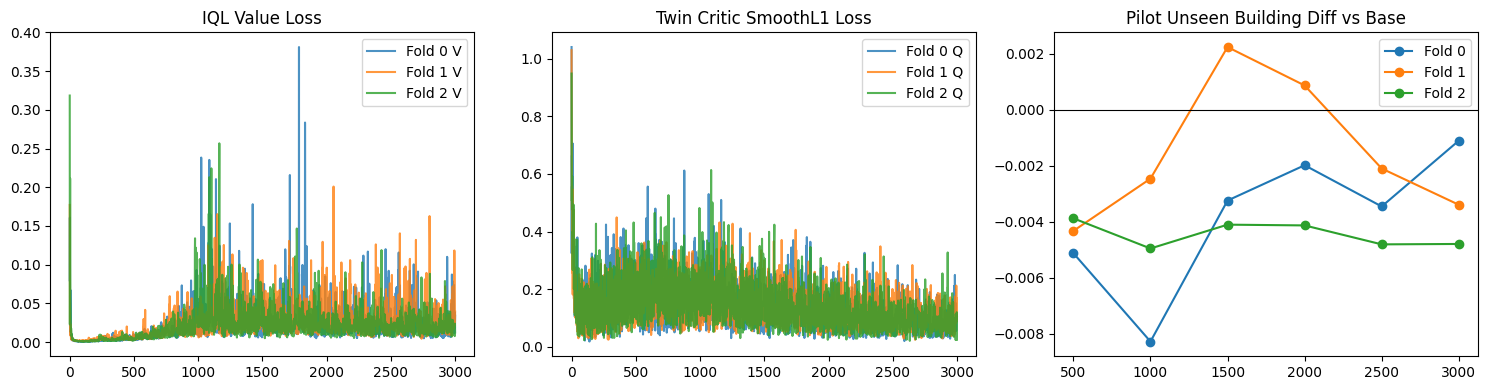

In [3]:
# Cell 3: Huan luyen 3-Fold Stochastic IQL-AWR + Epistemic Penalty + CAPS + Safety Shield
def run_eval(sc_list, actors, steps=STEPS_EVAL, smooth_alpha=0.5):
    scores = {}
    gate_sums = np.zeros(AHU_ACT_DIM, dtype=np.float64)
    total_steps = 0
    shield_checks, shield_hits = 0, 0
    for sc in sc_list:
        k = f'{sc.parts[-2]}/{sc.parts[-1]}'
        env = load_hybrid_environment(sc / 'config.gin')
        obs, _ = env.reset()
        meta = create_building_meta_data(env, sc)
        pol = WARP_CLS(
            meta, env.action_spec(), actors=actors, dev=device,
            smooth_alpha=smooth_alpha, comfort_shield=COMFORT_SHIELD,
            target_water_only=TARGET_WATER_ONLY,
        )
        ep_r = 0.0
        for _ in range(steps):
            act = pol.get_action(obs)
            obs, r, _, _, _ = env.step(act)
            ep_r += r
            gate_sums += np.asarray(pol._last_gate, dtype=np.float64)
            total_steps += 1
        scores[k] = float(ep_r)
        shield_checks += int(getattr(pol, '_shield_checks', 0))
        shield_hits += int(getattr(pol, '_shield_hits', 0))
    diffs = [scores[k] - BASE_SCORES[k] for k in scores]
    mean_gate = gate_sums / max(total_steps, 1)
    shield_rate = float(shield_hits / max(shield_checks, 1)) if shield_checks > 0 else 0.0
    return float(np.mean(list(scores.values()))), float(np.mean(diffs)), scores, mean_gate, shield_rate

if not SKIP_TRAIN:
    # Sanity check Zero-Difference voi actors=[]
    sc0 = ALL_SCENARIOS[0]
    k0 = f'{sc0.parts[-2]}/{sc0.parts[-1]}'
    _, zdiff, _, _, _ = run_eval([sc0], [], steps=STEPS_EVAL)
    print(f'Zero-Difference Sanity ({k0}): diff = {zdiff:.8f}')
    assert abs(zdiff) < 1e-6, 'Zero-Difference Physics Parity bi lech!'

    pilot_scs = [next(sc for sc in ALL_SCENARIOS if sc.parts[-2] in val_b) for val_b in FOLDS_3]
    fold_curves = []

    for fold in FOLDS_TO_RUN:
        val_bldgs = set(FOLDS_3[fold])
        tr_mask = np.array([b not in val_bldgs for b in BUF['bldg']])
        tr_idx = np.where(tr_mask)[0]
        probs_tr = build_balanced_probs(tr_idx, BUF['r_n'])

        # Chuan hoa tuyen tinh theo std (KHONG dung symlog de bao toan ty le phat comfort)
        rew_scale = float(np.clip(np.std(BUF['r_n'][tr_idx]), 1e-2, 10.0))

        vnet = DeepSetsValueNet().to(device)
        critic = DeepSetsAHUTwinCritic().to(device)
        critic_tgt = copy.deepcopy(critic).eval()
        actor = DeepSetsWarpResiPActor().to(device)

        opt_v = torch.optim.AdamW(vnet.parameters(), lr=LR_V, weight_decay=1e-4)
        opt_q = torch.optim.AdamW(critic.parameters(), lr=LR_Q, weight_decay=1e-4)
        opt_a = torch.optim.AdamW(actor.parameters(), lr=LR_A, weight_decay=1e-4)
        sched_a = torch.optim.lr_scheduler.CosineAnnealingLR(opt_a, T_max=TRAIN_ITERS)

        best_saved_diff = 0.0
        best_trained_diff = -1e9
        best_state = {k: v.cpu() for k, v in actor.state_dict().items()}
        trained_state = None
        v_hist, q_hist, a_hist, p_hist = [], [], [], []
        pilot_sc = pilot_scs[fold]

        pbar = tqdm(range(1, TRAIN_ITERS + 1), desc=f'Fold {fold} Val={list(val_bldgs)}')
        for it in pbar:
            bi = np.random.choice(tr_idx, size=BATCH_SIZE, replace=True, p=probs_tr)
            zc_b = torch.from_numpy(BUF['z_cur'][bi]).to(device)
            mc_b = torch.from_numpy(BUF['m_cur'][bi]).to(device)
            gc_b = torch.from_numpy(BUF['g_cur'][bi]).to(device)
            xb_b = torch.from_numpy(BUF['xb_cur'][bi]).to(device)
            xe_b = torch.from_numpy(BUF['xe_cur'][bi]).to(device)
            rn_b = torch.from_numpy(BUF['r_n'][bi]).to(device) / rew_scale
            zn_b = torch.from_numpy(BUF['z_nxt'][bi]).to(device)
            mn_b = torch.from_numpy(BUF['m_nxt'][bi]).to(device)
            gn_b = torch.from_numpy(BUF['g_nxt'][bi]).to(device)
            xbn_b = torch.from_numpy(BUF['xb_nxt'][bi]).to(device)

            # 1. IQL Expectile Regression cho V(s)
            vnet.train(); critic.train(); actor.train()
            with torch.no_grad():
                q1_t, q2_t = critic_tgt(zc_b, mc_b, gc_b, xe_b)
                q_min_t = torch.min(q1_t, q2_t)
            v_pred = vnet(zc_b, mc_b, gc_b)
            diff_v = q_min_t - v_pred
            w_exp = torch.where(diff_v > 0, IQL_TAU, 1.0 - IQL_TAU)
            loss_v = (w_exp * (diff_v ** 2)).mean()
            opt_v.zero_grad(); loss_v.backward(); nn.utils.clip_grad_norm_(vnet.parameters(), 1.0); opt_v.step()

            # 2. Twin Critic Backup dung V(s') (Khong query hanh dong OOD!)
            with torch.no_grad():
                v_nxt = vnet(zn_b, mn_b, gn_b)
                target_q = rn_b + GAMMA_N * v_nxt
            q1, q2 = critic(zc_b, mc_b, gc_b, xe_b)
            loss_q = F.smooth_l1_loss(q1, target_q, beta=2.0) + F.smooth_l1_loss(q2, target_q, beta=2.0)
            opt_q.zero_grad(); loss_q.backward(); nn.utils.clip_grad_norm_(critic.parameters(), 1.0); opt_q.step()

            # 3. Stochastic IQL-AWR + Epistemic Penalty + CAPS
            with torch.no_grad():
                q1_b, q2_b = critic_tgt(zc_b, mc_b, gc_b, xe_b)
                v_cur = vnet(zc_b, mc_b, gc_b)
                q_cons = torch.min(q1_b, q2_b) - EPI_PENALTY * torch.abs(q1_b - q2_b)
                adv = (q_cons - v_cur).squeeze(-1)
                awr_w = torch.exp(BETA_AWR * adv).clamp(max=MAX_AWR_WEIGHT)

            log_pi, _, _, _ = actor.log_prob(zc_b, mc_b, gc_b, xb_b, xe_b)
            loss_awr = -(awr_w * log_pi).mean()

            x_exp_c, _, _, _ = actor(zc_b, mc_b, gc_b, xb_b)
            eps_z = torch.randn_like(zc_b) * CAPS_SPATIAL_STD
            eps_g = torch.randn_like(gc_b) * CAPS_SPATIAL_STD
            x_exp_p, _, _, _ = actor(zc_b + eps_z, mc_b, gc_b + eps_g, xb_b)
            x_exp_n, _, _, _ = actor(zn_b, mn_b, gn_b, xbn_b)
            dx_c = x_exp_c - xb_b
            dx_p = x_exp_p - xb_b
            dx_n = x_exp_n - xbn_b
            loss_caps = CAPS_LAMBDA_S * F.mse_loss(dx_p, dx_c.detach()) + CAPS_LAMBDA_T * F.mse_loss(dx_n, dx_c)
            loss_id = 0.05 * (dx_c ** 2).mean()
            loss_a = loss_awr + loss_caps + loss_id

            opt_a.zero_grad(); loss_a.backward(); nn.utils.clip_grad_norm_(actor.parameters(), 1.0); opt_a.step()
            sched_a.step()

            with torch.no_grad():
                for p, pt in zip(critic.parameters(), critic_tgt.parameters()):
                    pt.data.mul_(1.0 - POLYAK_TAU).add_(POLYAK_TAU * p.data)

            v_hist.append(float(loss_v.item()))
            q_hist.append(float(loss_q.item()))
            a_hist.append(float(loss_a.item()))

            if it % EVAL_EVERY == 0:
                actor.eval()
                _, d_p, _, g_p, sh_p = run_eval([pilot_sc], [actor], steps=STEPS_EVAL)
                p_hist.append((it, d_p))
                if d_p > best_trained_diff:
                    best_trained_diff = d_p
                    trained_state = {k: v.cpu() for k, v in actor.state_dict().items()}
                if d_p >= best_saved_diff:
                    best_saved_diff = d_p
                    best_state = {k: v.cpu() for k, v in actor.state_dict().items()}
                pbar.set_postfix(V=f'{v_hist[-1]:.3f}', Q=f'{q_hist[-1]:.3f}', PilotDiff=f'{d_p:+.4f}', Shield=f'{sh_p*100:.1f}%')

        torch.save(best_state, OUT_DIR / f'warp_resip_{BASE_MODE}_fold{fold}.pt')
        if trained_state is not None:
            torch.save(trained_state, OUT_DIR / f'warp_resip_{BASE_MODE}_fold{fold}_raw_trained.pt')
        print(f'Fold {fold} xong | BestTrainedPilotDiff: {best_trained_diff:+.4f} | SavedSafeDiff: {best_saved_diff:+.4f}')
        fold_curves.append({'fold': fold, 'v': v_hist, 'q': q_hist, 'a': a_hist, 'p': p_hist})

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for fc in fold_curves:
        axes[0].plot(fc['v'], alpha=0.8, label=f'Fold {fc["fold"]} V')
        axes[1].plot(fc['q'], alpha=0.8, label=f'Fold {fc["fold"]} Q')
        if fc['p']:
            xs, ys = zip(*fc['p'])
            axes[2].plot(xs, ys, marker='o', label=f'Fold {fc["fold"]}')
    axes[0].set_title('IQL Value Loss'); axes[0].legend()
    axes[1].set_title('Twin Critic SmoothL1 Loss'); axes[1].legend()
    axes[2].axhline(0.0, color='black', lw=0.8)
    axes[2].set_title('Pilot Unseen Building Diff vs Base'); axes[2].legend()
    plt.tight_layout(); plt.savefig(OUT_DIR / 'stage2_iql_curves.png', dpi=150); plt.show()


=== KET QUA 3-FOLD OOF (ZERO-LEAK) TREN TOAN BO 30 KICH BAN ===
                           base  warp_iql      diff  shield_rate
fold building                                                   
0    building_train_1 -6.683604 -6.683604  0.000000     0.000000
     building_train_7 -3.821315 -3.821315  0.000000     0.000000
1    building_train_2 -7.522671 -7.525964 -0.003294     0.043161
     building_train_5 -2.416424 -2.417226 -0.000803     0.043161
2    building_train_4 -3.394315 -3.394315  0.000000     0.000000
     building_train_8 -6.577006 -6.577006  0.000000     0.000000
------------------------------------------------------------------------
OOF Mean Base     : -5.0692
OOF Mean Warp-IQL : -5.0699 (Diff: -0.0007)
Mean 4D ResiP Gate [SAT, Press, Recirc, Water]: [0.0541 0.079  0.0751 0.0781]


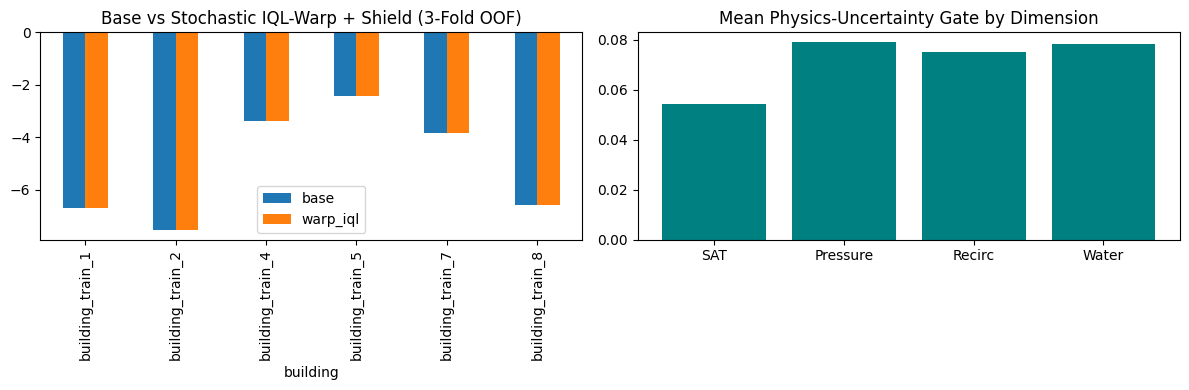

In [3]:
# Cell 4: Danh gia Full 3-Fold OOF (Zero-Leak) + Kiem tra Safety Shield & Gate
if not IS_RERUN:
    oof_rows, fold_gates = [], []
    for fold in FOLDS_TO_RUN:
        val_bldgs = set(FOLDS_3[fold])
        val_scs = [sc for sc in ALL_SCENARIOS if sc.parts[-2] in val_bldgs]
        ckpt_p = OUT_DIR / f'warp_resip_{BASE_MODE}_fold{fold}.pt'
        net = DeepSetsWarpResiPActor().to(device)
        net.load_state_dict(torch.load(ckpt_p, map_location=device, weights_only=True))
        net.eval()

        _, _, sc_scores, mg, sh_rate = run_eval(val_scs, [net], steps=STEPS_EVAL)
        fold_gates.append(mg)
        for k, s_val in sc_scores.items():
            bldg = k.split('/')[0]
            oof_rows.append({
                'fold': fold, 'building': bldg, 'scenario': k,
                'base': BASE_SCORES[k], 'warp_iql': s_val,
                'diff': s_val - BASE_SCORES[k], 'shield_rate': sh_rate
            })

    df_oof = pd.DataFrame(oof_rows)
    df_oof.to_csv(OUT_DIR / 'oof_stage2_iql_warp.csv', index=False)
    print('=== KET QUA 3-FOLD OOF (ZERO-LEAK) TREN TOAN BO 30 KICH BAN ===')
    print(df_oof.groupby(['fold', 'building'])[['base', 'warp_iql', 'diff', 'shield_rate']].mean().to_string())
    print('-' * 72)
    print(f'OOF Mean Base     : {df_oof["base"].mean():.4f}')
    print(f'OOF Mean Warp-IQL : {df_oof["warp_iql"].mean():.4f} (Diff: {df_oof["diff"].mean():+.4f})')

    mean_gate_all = np.mean(fold_gates, axis=0)
    print(f'Mean 4D ResiP Gate [SAT, Press, Recirc, Water]: {np.round(mean_gate_all, 4)}')

    cfg = {'base_mode': BASE_MODE, 'comfort_shield': COMFORT_SHIELD, 'target_water_only': TARGET_WATER_ONLY}
    (OUT_DIR / 'stage2_config.json').write_text(json.dumps(cfg, indent=2))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    b_stats = df_oof.groupby('building')[['base', 'warp_iql']].mean()
    b_stats.plot(kind='bar', ax=axes[0]); axes[0].set_title('Base vs Stochastic IQL-Warp + Shield (3-Fold OOF)')
    axes[1].bar(['SAT', 'Pressure', 'Recirc', 'Water'], mean_gate_all, color='teal')
    axes[1].set_title('Mean Physics-Uncertainty Gate by Dimension')
    plt.tight_layout(); plt.savefig(OUT_DIR / 'oof_stage2_iql_warp.png', dpi=150); plt.show()


In [ ]:
# Cell 5: Kaggle 3-Fold Ensemble Submission (WarpResiP + Safety Shield)
from kaggle_evaluation import smart_buildings_inference_server

class SubmissionWarpIQLPolicy(WARP_CLS, smart_buildings_inference_server.Policy):
    def __init__(self, building_meta_data, action_spec=None, parameters=None):
        infer_dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        ckpts = sorted(list(OUT_DIR.glob(f'warp_resip_{BASE_MODE}_fold*.pt')))
        ckpts = [p for p in ckpts if '_raw_trained' not in p.name]
        if not ckpts and Path('/kaggle/input').exists():
            ckpts = sorted([p for p in Path('/kaggle/input').rglob(f'warp_resip_{BASE_MODE}_fold*.pt')
                            if '_raw_trained' not in p.name])
        actors = []
        for p in ckpts:
            net = DeepSetsWarpResiPActor().to(infer_dev)
            net.load_state_dict(torch.load(p, map_location=infer_dev, weights_only=True))
            net.eval()
            actors.append(net)
        cfg_hits = list(OUT_DIR.glob('stage2_config.json'))
        if not cfg_hits and Path('/kaggle/input').exists():
            cfg_hits = sorted(list(Path('/kaggle/input').rglob('stage2_config.json')))
        shield = COMFORT_SHIELD
        w_only = TARGET_WATER_ONLY
        if cfg_hits:
            cfg = json.loads(cfg_hits[-1].read_text())
            shield = bool(cfg.get('comfort_shield', shield))
            w_only = bool(cfg.get('target_water_only', w_only))
        super().__init__(building_meta_data, action_spec, parameters,
                         actors=actors, dev=infer_dev, smooth_alpha=0.5,
                         comfort_shield=shield, target_water_only=w_only)

inference_server = smart_buildings_inference_server.SmartBuildingsInferenceServer(SubmissionWarpIQLPolicy)
if IS_RERUN:
    inference_server.run()
else:
    print('Da san sang Submit Stochastic IQL-Warp + Physics Safety Shield!')
